In [940]:
import pandas as pd
import numpy as np
import seaborn  as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')


In [941]:
data =pd.read_csv('/content/quickbite_customers.csv')

In [942]:
data.head()

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend
0,QB100000,2023-11-27,Lucknow,2,Female,Android,Referral,21.0,35.6,13,45.3,572.0,NaN,21.6,4.0,Basic,17,8675.0
1,QB100001,2025-05-26,Bengaluru,1,Female,iOS,Influencer,43.0,17.4,11,21.9,329.0,4.9,0.0,13.0,Basic,24,7896.0
2,QB100002,2023-02-06,Indore,3,Male,iOS,Referral,39.0,45.4,12,47.9,118.0,3.8,17.8,1.0,Basic,17,1826.0
3,QB100003,2024-04-09,Jaipur,2,Female,Android,Paid Social,34.0,31.2,13,26.4,303.0,NaN,42.9,7.0,Basic,379,90202.0
4,QB100004,2025-04-12,Mumbai,1,Male,Android,Search Ads,33.0,18.9,17,19.4,191.0,4.0,29.2,12.0,Basic,17,2773.0


Task 0: Setup and First Look

In [943]:
data.head()

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend
0,QB100000,2023-11-27,Lucknow,2,Female,Android,Referral,21.0,35.6,13,45.3,572.0,NaN,21.6,4.0,Basic,17,8675.0
1,QB100001,2025-05-26,Bengaluru,1,Female,iOS,Influencer,43.0,17.4,11,21.9,329.0,4.9,0.0,13.0,Basic,24,7896.0
2,QB100002,2023-02-06,Indore,3,Male,iOS,Referral,39.0,45.4,12,47.9,118.0,3.8,17.8,1.0,Basic,17,1826.0
3,QB100003,2024-04-09,Jaipur,2,Female,Android,Paid Social,34.0,31.2,13,26.4,303.0,NaN,42.9,7.0,Basic,379,90202.0
4,QB100004,2025-04-12,Mumbai,1,Male,Android,Search Ads,33.0,18.9,17,19.4,191.0,4.0,29.2,12.0,Basic,17,2773.0


In [944]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             2000 non-null   object 
 1   signup_date             2000 non-null   object 
 2   city                    2000 non-null   object 
 3   city_tier               2000 non-null   int64  
 4   gender                  1894 non-null   object 
 5   device_type             2000 non-null   object 
 6   acquisition_channel     2000 non-null   object 
 7   age                     1861 non-null   float64
 8   tenure_months           2000 non-null   float64
 9   app_sessions_per_month  2000 non-null   int64  
 10  delivery_time_min       1920 non-null   float64
 11  avg_order_value         1892 non-null   float64
 12  customer_rating         1742 non-null   float64
 13  discount_used_pct       1896 non-null   float64
 14  days_since_last_order   2000 non-null   

In [945]:
data['signup_date']=pd.to_datetime(data['signup_date'])

In [946]:
data.describe()

,signup_date,city_tier,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,orders_last_12m,annual_spend
count,2000,2000.000000,1861.000000,2000.000000,2000.00000,1920.000000,1892.000000,1742.000000,1896.000000,2000.000000,2000.00000,2000.000000
mean,2024-05-28 18:57:35.999999744,1.600500,31.926384,29.507300,13.93200,34.991198,417.577696,4.290356,22.499947,18.599500,34.89650,12995.852000
min,2023-01-01 00:00:00,1.000000,0.000000,12.000000,2.00000,15.600000,57.000000,1.000000,0.000000,0.000000,5.00000,523.000000
25%,2023-09-18 18:00:00,1.000000,27.000000,20.775000,11.00000,26.200000,215.000000,4.000000,16.200000,5.000000,17.00000,4085.750000
50%,2024-05-29 12:00:00,1.000000,32.000000,29.500000,14.00000,32.250000,315.500000,4.400000,22.400000,12.000000,24.00000,7142.000000
75%,2025-02-15 06:00:00,2.000000,37.000000,37.925000,16.00000,40.500000,458.250000,4.700000,28.500000,26.000000,32.00000,12781.250000
max,2025-11-05 00:00:00,3.000000,150.000000,46.600000,29.00000,500.000000,32000.000000,5.000000,55.900000,125.000000,400.00000,855443.000000
std,NaN,0.772138,7.619334,9.981302,3.77856,19.486015,1133.673898,0.609572,9.483931,18.983606,49.27424,30336.382856


In [947]:
# Column	         Minimum	     Maximum	Initial observation
# age	               0	          150	    Possible invalid ages
# delivery_time_min	 15.6	        500	    Extreme delivery time
# avg_order_value	   57	          32,000	Extreme order value
# annual_spend	     523          855443	Potentially high-spending customers
# orders_last_12m	    5	           400	  Potentially unusual order count

The descriptive statistics indicate potential outliers across several numerical variables. The most significant anomalies appear in age,
delivery_time_min, avg_order_value, orders_last_12m,and annual_spend. These variables exhibit substantial differences between their median
and maximum values, suggesting highly skewed distributions and potentially influential observations.

In [948]:
data.describe(include='all')

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend
count,2000,2000,2000,2000.000000,1894,2000,2000,1861.000000,2000.000000,2000.00000,1920.000000,1892.000000,1742.000000,1896.000000,2000.000000,2000,2000.00000,2000.000000
unique,2000,NaN,10,NaN,3,3,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,NaN,NaN
top,QB100000,NaN,Mumbai,NaN,Male,Android,Organic,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Basic,NaN,NaN
freq,1,NaN,320,NaN,1023,1171,592,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1179,NaN,NaN
mean,NaN,2024-05-28 18:57:35.999999744,NaN,1.600500,NaN,NaN,NaN,31.926384,29.507300,13.93200,34.991198,417.577696,4.290356,22.499947,18.599500,NaN,34.89650,12995.852000
min,NaN,2023-01-01 00:00:00,NaN,1.000000,NaN,NaN,NaN,0.000000,12.000000,2.00000,15.600000,57.000000,1.000000,0.000000,0.000000,NaN,5.00000,523.000000
25%,NaN,2023-09-18 18:00:00,NaN,1.000000,NaN,NaN,NaN,27.000000,20.775000,11.00000,26.200000,215.000000,4.000000,16.200000,5.000000,NaN,17.00000,4085.750000
50%,NaN,2024-05-29 12:00:00,NaN,1.000000,NaN,NaN,NaN,32.000000,29.500000,14.00000,32.250000,315.500000,4.400000,22.400000,12.000000,NaN,24.00000,7142.000000
75%,NaN,2025-02-15 06:00:00,NaN,2.000000,NaN,NaN,NaN,37.000000,37.925000,16.00000,40.500000,458.250000,4.700000,28.500000,26.000000,NaN,32.00000,12781.250000
max,NaN,2025-11-05 00:00:00,NaN,3.000000,NaN,NaN,NaN,150.000000,46.600000,29.00000,500.000000,32000.000000,5.000000,55.900000,125.000000,NaN,400.00000,855443.000000


In [949]:
# Report the missing-value count and percentage per column (a Seaborn heatmap of
# df.isna() is a nice visual).

In [950]:
missing_count=data.isnull().sum()
missing_percentage=(missing_count/len(data))*100
missing_summary=pd.DataFrame({'missing_count':missing_count,'missing_percentage':missing_percentage})
missing_summary.sort_values(by='missing_percentage',ascending=False)

,missing_count,missing_percentage
customer_rating,258,12.90
age,139,6.95
avg_order_value,108,5.40
gender,106,5.30
discount_used_pct,104,5.20
delivery_time_min,80,4.00
signup_date,0,0.00
customer_id,0,0.00
city_tier,0,0.00
city,0,0.00


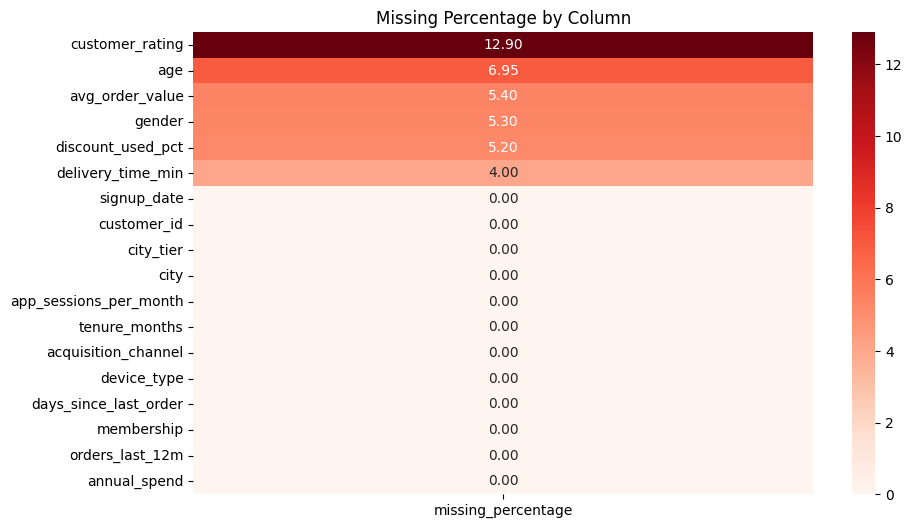

In [951]:
plt.figure(figsize=(10, 6))

sns.heatmap(missing_summary[['missing_percentage']].sort_values(by='missing_percentage', ascending=False),
    annot=True,fmt='.2f',cmap='Reds')

plt.title('Missing Percentage by Column')
plt.show()

Task 1: Missing Value Imputation.
1.Age Fill with median (after outlier treatment) Why median,not
mean?

Median is preferable because age may contain outliers, and extreme values can distort the mean.

In [952]:
data['age'].describe()

,age
count,1861.000000
mean,31.926384
std,7.619334
min,0.000000
25%,27.000000
50%,32.000000
75%,37.000000
max,150.000000


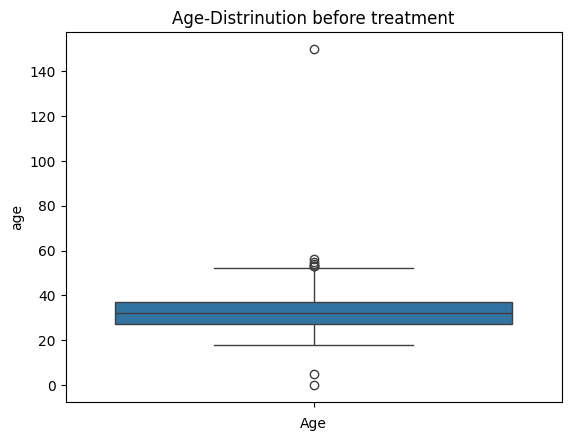

In [953]:
sns.boxplot(data['age'])
plt.title('Age-Distrinution before treatment')
plt.xlabel('Age')
plt.show()

In [954]:
data[data['age']>=100]

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend
1617,QB101617,2023-07-11,Hyderabad,1,Female,iOS,Referral,150.0,40.3,13,35.9,305.0,3.1,37.4,12.0,Basic,24,5952.0


In [955]:
data[data['age']<=0]

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend
1792,QB101792,2024-02-12,Delhi,1,Male,iOS,Paid Social,0.0,33.1,14,28.0,239.0,2.7,27.8,27.0,Silver,20,4528.0


In [956]:
# both values as invalid  replacing them with NaN (missing values). We will then calculate the median using the remaining valid ages.

In [957]:
data.loc[data['age']>100,'age']=np.nan

In [958]:
data[data['age']>100]

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend


In [959]:
data.loc[data['age']<=0,'age']=np.nan

In [960]:
data[data['age']<=0]

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend


In [961]:
data['age'].describe()

,age
count,1859.000000
mean,31.880043
std,7.075491
min,5.000000
25%,27.000000
50%,32.000000
75%,37.000000
max,56.000000


In [962]:
data['age'].isnull().sum()

np.int64(141)

In [963]:
age_median=data['age'].median()
age_median

32.0

In [964]:
data['age']=data['age'].fillna(age_median)

In [965]:
data['age'].isna().sum()

np.int64(0)

Delivery time (delivery_time_min)

In [966]:
data['delivery_time_min'].describe()

,delivery_time_min
count,1920.000000
mean,34.991198
std,19.486015
min,15.600000
25%,26.200000
50%,32.250000
75%,40.500000
max,500.000000


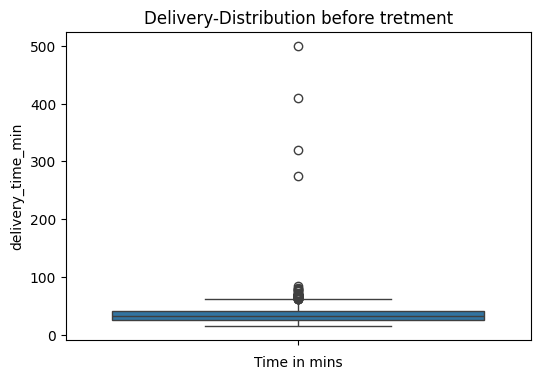

In [967]:
plt.figure(figsize=(6,4))
sns.boxplot(data['delivery_time_min'])
plt.title('Delivery-Distribution before tretment')
plt.xlabel('Time in mins')
plt.show()

In [968]:
data[data['delivery_time_min']>100]


,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend
1210,QB101210,2023-04-16,Jaipur,2,Female,Android,Paid Social,33.0,43.1,14,410.0,294.0,4.8,15.7,15.0,Basic,17,4605.0
1223,QB101223,2025-05-02,Pune,2,Male,Android,Influencer,37.0,18.2,10,275.0,178.0,4.5,30.4,27.0,Basic,20,3020.0
1293,QB101293,2025-01-28,Bengaluru,1,Female,Web,Organic,33.0,21.4,12,320.0,169.0,4.8,21.7,1.0,Basic,24,3616.0
1417,QB101417,2023-06-27,Hyderabad,1,Male,Android,Search Ads,43.0,40.7,19,500.0,273.0,5.0,13.3,4.0,Platinum,20,7390.0


In [969]:
data[data['delivery_time_min']>100].shape

(4, 18)

In [970]:
# we can not remove the data because  i can see the customer  rating for these delivery is high let's checking the impact after removing these data

In [971]:
print('Original_average:',round(np.average(data['delivery_time_min']),2))

Original_average: nan


In [972]:
print('Average excluding extreme records:',round(data.loc[data['delivery_time_min'] <= 100, 'delivery_time_min'].mean(),2))

Average excluding extreme records: 34.28


In [973]:
data['delivery_time_min'].skew()

np.float64(13.552453437640326)

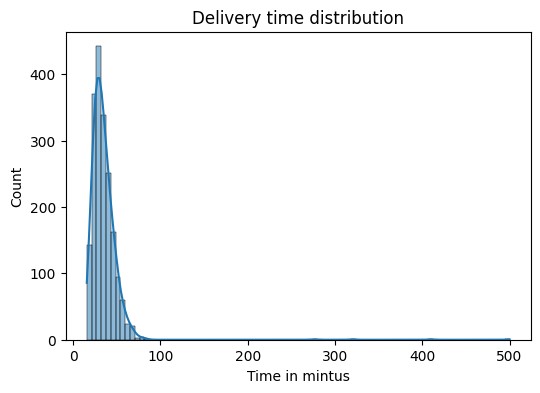

In [974]:
plt.figure(figsize=(6,4))
sns.histplot(data=data,x='delivery_time_min',kde=True)
plt.title('Delivery time distribution')
plt.xlabel('Time in mintus')
plt.show()

In [975]:
delivery_median=data['delivery_time_min'].median()
print(delivery_median)

32.25


In [976]:
data['delivery_time_min']=data['delivery_time_min'].fillna(delivery_median)

In [977]:
data['delivery_time_min'].isna().sum()

np.int64(0)

In [978]:
data['delivery_time_min'].describe()

,delivery_time_min
count,2000.000000
mean,34.881550
std,19.099677
min,15.600000
25%,26.500000
50%,32.250000
75%,40.100000
max,500.000000


Now let's check the avg_order_value

In [979]:
data['avg_order_value'].describe()

,avg_order_value
count,1892.000000
mean,417.577696
std,1133.673898
min,57.000000
25%,215.000000
50%,315.500000
75%,458.250000
max,32000.000000


The mean (₹417.58) is considerably higher than the median (₹315.50).

The maximum value (₹32,000) is extremely far above the 75th percentile (₹458.25).

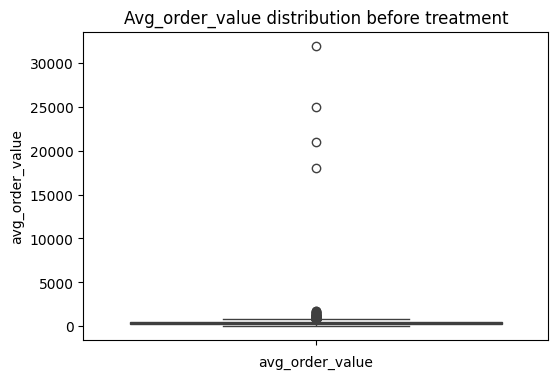

In [980]:
plt.figure(figsize=(6,4))
sns.boxplot(data=data['avg_order_value'])
plt.title("Avg_order_value distribution before treatment")
plt.xlabel('avg_order_value')
plt.show()

In [981]:
data[data['avg_order_value']>15000]

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend
156,QB100156,2025-01-05,Delhi,1,Male,Android,Search Ads,18.0,22.1,10,38.1,18000.0,NaN,23.6,0.0,Basic,17,4964.0
567,QB100567,2025-01-01,Mumbai,1,Male,Android,Referral,23.0,22.3,18,29.8,32000.0,4.9,25.5,10.0,Gold,17,5061.0
693,QB100693,2025-06-16,Bengaluru,1,Female,iOS,Organic,33.0,16.7,15,27.5,25000.0,4.2,NaN,46.0,Basic,17,7519.0
1782,QB101782,2025-07-08,Delhi,1,Female,iOS,Influencer,29.0,16.0,10,33.4,21000.0,NaN,11.4,15.0,Basic,7,826.0


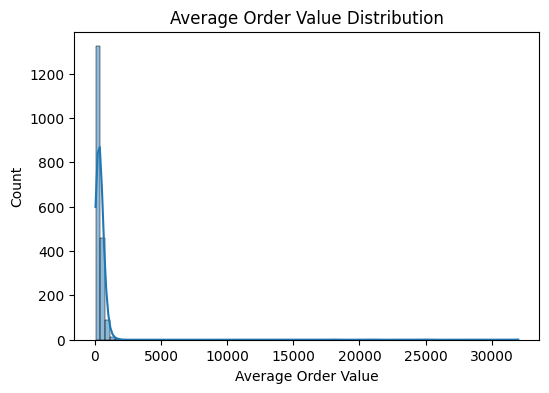

In [982]:
plt.figure(figsize=(6,4))
sns.histplot(data=data,x='avg_order_value',kde=True)
plt.title('Average Order Value Distribution')
plt.xlabel('Average Order Value')
plt.show()

In [983]:
data['avg_order_value'].skew()
# this show the strong right skewed

np.float64(21.993512750673542)

In [984]:
data.loc[
    data['avg_order_value'] <= 1000,
    'avg_order_value'
].describe()

,avg_order_value
count,1857.000000
mean,353.062466
std,188.317824
min,57.000000
25%,213.000000
50%,311.000000
75%,450.000000
max,995.000000


In [985]:
data.loc[
    data['avg_order_value'] <= 1000,
    'avg_order_value'
].skew()

np.float64(1.09071767030087)

In [986]:
data[data['avg_order_value']>15000].shape

(4, 18)

In [987]:
data[data['avg_order_value']>1000].shape

(35, 18)

In [988]:
data.loc[data['avg_order_value']>15000,'avg_order_value']=np.nan

In [989]:
data['avg_order_value'].isna().sum()

np.int64(112)

In [990]:
data.loc[data['avg_order_value'] > 15000, 'avg_order_value'] = np.nan

In [991]:
data['avg_order_value'].isna().sum()

np.int64(112)

In [992]:
data.groupby('city_tier')['avg_order_value'].median()

,avg_order_value
city_tier,
1,325.0
2,309.0
3,289.5


In [993]:
data['avg_order_value'] = data['avg_order_value'].fillna(
    data.groupby('city_tier')['avg_order_value'].transform('median')
)

In [994]:
data['avg_order_value']=data['avg_order_value'].fillna(data.groupby('city_tier')['avg_order_value'].transform('median'))

In [995]:
data['avg_order_value'].isna().sum()

np.int64(0)

Imputing customer rating

In [996]:
data.groupby(data['customer_rating'].isna())['delivery_time_min'].median()

,delivery_time_min
customer_rating,
False,31.4
True,39.9


In [997]:
# Customers with missing ratings experienced a noticeably longer median delivery time

In [998]:
# checking the median by city tier


In [999]:
# checking the skeness

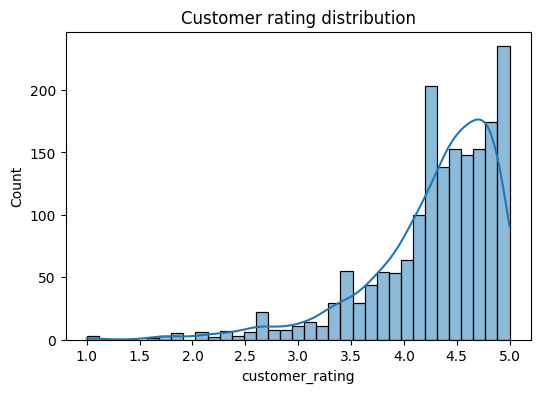

In [1000]:
plt.figure(figsize=(6,4))
sns.histplot(data=data,x='customer_rating',kde=True)
plt.title('Customer rating distribution')
plt.show()

In [1001]:
data.groupby('city_tier')['customer_rating'].median()

,customer_rating
city_tier,
1,4.4
2,4.5
3,4.4


In [1002]:
data['customer_rating']=data['customer_rating'].fillna(data.groupby('city_tier')['customer_rating'].transform('median'))

In [1003]:
data['customer_rating'].isna().sum()

np.int64(0)

Imputing the discount_used_pct

In [1004]:
data['discount_used_pct'].describe()

,discount_used_pct
count,1896.000000
mean,22.499947
std,9.483931
min,0.000000
25%,16.200000
50%,22.400000
75%,28.500000
max,55.900000


In [1005]:
data['discount_used_pct'].skew()

np.float64(0.13284539343657606)

In [1006]:
# I can see mean is near to  median almost  and skwness is showing data is symmetrically distributed.

In [1007]:
data['discount_used_pct']=data['discount_used_pct'].fillna(data['discount_used_pct'].mean())

In [1008]:
data['discount_used_pct'].isna().sum()

np.int64(0)

Imputing the gender

In [1009]:
data['gender'].value_counts(normalize=True)

,proportion
gender,
Male,0.540127
Female,0.441394
Other,0.018479


In [1010]:
data['gender'].value_counts()

,count
gender,
Male,1023
Female,836
Other,35


In [1011]:
data['gender']=data['gender'].fillna('Unknown')

In [1012]:
data['gender'].describe()

,gender
count,2000
unique,4
top,Male
freq,1023


In [1013]:
data['gender'].isna().sum()

np.int64(0)

In [1014]:
# Four extreme delivery times (275–500 minutes) were retained for investigation rather than automatically deleted.
# Four suspicious average order values above ₹15,000 were treated as missing.
# Missing customer ratings were associated with longer median delivery times (39.9 vs. 31.4 minutes).
# Missing gender values were labelled "Unknown" to avoid assuming customers' gender.

Outlier Detection and Removal

In [1015]:
data.isna().sum()

,0
customer_id,0
signup_date,0
city,0
city_tier,0
gender,0
device_type,0
acquisition_channel,0
age,0
tenure_months,0
app_sessions_per_month,0


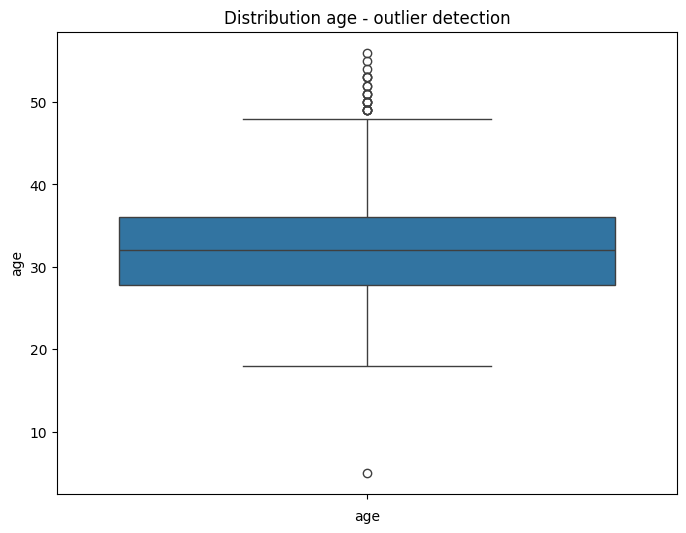

In [1016]:
plt.figure(figsize=(8,6))
sns.boxplot(data=data['age'])
plt.title('Distribution age - outlier detection')
plt.xlabel('age')
plt.show()

In [1017]:
Q1=data['age'].quantile(0.25)
Q3=data['age'].quantile(0.75)
IQR=Q3-Q1

In [1018]:
upper_bound=Q3+1.5*IQR
lower_bound=Q1-1.5*IQR

In [1019]:
print('Q1:',Q1)
print('Q3:',Q3)
print('IQR:',IQR)
print('upper_bound:',upper_bound)
print('lower_bound:',lower_bound)

Q1: 27.75
Q3: 36.0
IQR: 8.25
upper_bound: 48.375
lower_bound: 15.375


In [1020]:
age_outlier=data[(data['age']<lower_bound) | (data['age']>upper_bound)]
age_outlier[['customer_id','age','city','annual_spend']]

,customer_id,age,city,annual_spend
215,QB100215,51.0,Jaipur,9652.0
241,QB100241,49.0,Lucknow,9408.0
245,QB100245,5.0,Indore,8410.0
257,QB100257,56.0,Mumbai,10054.0
384,QB100384,49.0,Bengaluru,21375.0
459,QB100459,55.0,Pune,11055.0
572,QB100572,53.0,Hyderabad,16332.0
606,QB100606,50.0,Indore,9148.0
688,QB100688,50.0,Jaipur,22190.0
762,QB100762,51.0,Mumbai,4952.0


In [1021]:
len(age_outlier)

21

In [1022]:
data.loc[data['age']==5,['customer_id','age','city','gender','membership','orders_last_12m','annual_spend']]

,customer_id,age,city,gender,membership,orders_last_12m,annual_spend
245,QB100245,5.0,Indore,Female,Basic,17,8410.0


In [1023]:
# this tell that customer has significant records  that can age might be invalid because this records have good numbers of purchases records so,
# there is chances of having incorrect age filled.

In [1024]:
data.loc[data['age']==5,'age']=np.nan

In [1025]:
data['age']=data['age'].fillna(data['age'].median)

In [1026]:
data['age'].isna().sum()

np.int64(0)

In [1027]:
# Age — Final decisions
# - Ages 49–56: Retained because they are realistic customer ages.
# - Age 5: Treated as invalid and replaced with the median.
# - Ages 0 and 150: Previously treated as invalid and imputed.
# - All 2,000 customer records preserved.

Delivery-time outlier detection

In [1028]:
data['delivery_time_min'].describe()

,delivery_time_min
count,2000.000000
mean,34.881550
std,19.099677
min,15.600000
25%,26.500000
50%,32.250000
75%,40.100000
max,500.000000


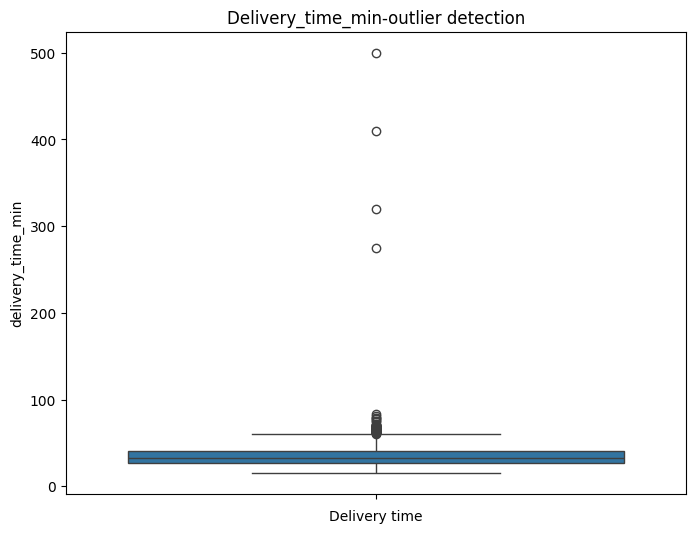

In [1029]:
plt.figure(figsize=(8,6))
sns.boxplot(data=data['delivery_time_min'])
plt.title('Delivery_time_min-outlier detection')
plt.xlabel('Delivery time')
plt.show()

In [1030]:
Q1=data['delivery_time_min'].quantile(0.25)
Q3=data['delivery_time_min'].quantile(0.75)

IQR=Q3-Q1

upper_bound=Q3+1.5*IQR
lower_bound=Q1-1.5*IQR

In [1031]:
print(Q1)
print(Q3)
print(IQR)
print(upper_bound)
print(lower_bound)

26.5
40.1
13.600000000000001
60.5
6.099999999999998


In [1032]:
# I can see previously identified extreme values are above the upper bound.
delivery_time_min_outlier=data[(data['delivery_time_min']<lower_bound) | (data['delivery_time_min']>upper_bound)]

In [1033]:
delivery_time_min_outlier[['customer_id','delivery_time_min','customer_rating','city']].sort_values('delivery_time_min',ascending=False)

,customer_id,delivery_time_min,customer_rating,city
1417,QB101417,500.0,5.0,Hyderabad
1210,QB101210,410.0,4.8,Jaipur
1293,QB101293,320.0,4.8,Bengaluru
1223,QB101223,275.0,4.5,Pune
1616,QB101616,83.9,4.4,Mumbai
1090,QB101090,80.9,4.8,Delhi
48,QB100048,79.1,5.0,Jaipur
799,QB100799,79.0,4.9,Jaipur
222,QB100222,77.8,4.7,Pune
1925,QB101925,75.3,4.6,Mumbai


In [1034]:
len(delivery_time_min_outlier)

53

avg_order_value outlier detection

In [1035]:
data['avg_order_value'].isna().sum()

np.int64(0)

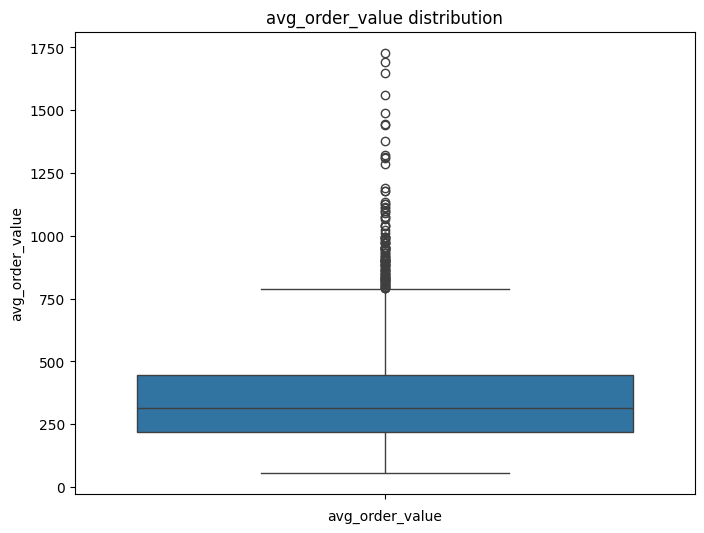

In [1036]:
plt.figure(figsize=(8,6))
sns.boxplot(data=data['avg_order_value'])
plt.title('avg_order_value distribution')
plt.xlabel('avg_order_value')
plt.show()

In [1037]:
# calculating IQR boundary

In [1038]:
Q1=data['avg_order_value'].quantile(0.25)
Q3=data['avg_order_value'].quantile(0.75)

IQR=Q3-Q1

upper_bound=Q3+1.5*IQR
lower_bound=Q1-1.5*IQR

print('Q1:',Q1)
print('Q3:',Q3)
print('IQR:',IQR)
print('upper_bound:',upper_bound)
print('lower_bound:',lower_bound)

Q1: 219.0
Q3: 446.5
IQR: 227.5
upper_bound: 787.75
lower_bound: -122.25


In [1039]:
order_outlier=data[data['avg_order_value']>upper_bound]

In [1040]:
order_outlier[['customer_id','city','city_tier','avg_order_value','orders_last_12m','annual_spend']]

,customer_id,city,city_tier,avg_order_value,orders_last_12m,annual_spend
17,QB100017,Mumbai,1,932.0,20,16058.0
32,QB100032,Bengaluru,1,955.0,17,14610.0
46,QB100046,Bengaluru,1,971.0,24,20240.0
77,QB100077,Pune,2,1176.0,20,20062.0
79,QB100079,Lucknow,2,900.0,61,76699.0
...,...,...,...,...,...,...
1853,QB101853,Jaipur,2,941.0,32,30508.0
1863,QB101863,Hyderabad,1,825.0,46,44567.0
1874,QB101874,Nagpur,3,1068.0,32,38662.0
1936,QB101936,Hyderabad,1,893.0,13,12138.0


In [1041]:
len(order_outlier)

106

In [1042]:
# Let's compare that estimate with the recorded annual_spend.

In [1043]:
data['estimated_annual_spend']=(data['avg_order_value']*data['orders_last_12m'])
order_outliers=data[data['avg_order_value']>upper_bound].copy()

order_outliers['spend_difference']=order_outliers['estimated_annual_spend']-order_outliers['annual_spend']

order_outliers[['customer_id','avg_order_value','orders_last_12m','estimated_annual_spend','annual_spend','spend_difference']].head(10)

,customer_id,avg_order_value,orders_last_12m,estimated_annual_spend,annual_spend,spend_difference
17,QB100017,932.0,20,18640.0,16058.0,2582.0
32,QB100032,955.0,17,16235.0,14610.0,1625.0
46,QB100046,971.0,24,23304.0,20240.0,3064.0
77,QB100077,1176.0,20,23520.0,20062.0,3458.0
79,QB100079,900.0,61,54900.0,76699.0,-21799.0
80,QB100080,898.0,17,15266.0,13571.0,1695.0
113,QB100113,1560.0,17,26520.0,29007.0,-2487.0
122,QB100122,1440.0,24,34560.0,31293.0,3267.0
126,QB100126,908.0,119,108052.0,119666.0,-11614.0
137,QB100137,794.0,24,19056.0,16749.0,2307.0


In [1044]:
len(order_outliers)

106

In [1045]:
# Let's calculate the percentage difference for all 106 records and identify the largest mismatches.

In [1046]:
order_outliers['difference_pct'] = (
    order_outliers['spend_difference'].abs() /
    order_outliers['annual_spend']
) * 100

order_outliers.sort_values(
    'difference_pct', ascending=False
)[['customer_id', 'avg_order_value',
   'orders_last_12m', 'annual_spend',
   'estimated_annual_spend', 'difference_pct']].head(10)

,customer_id,avg_order_value,orders_last_12m,annual_spend,estimated_annual_spend,difference_pct
967,QB100967,836.0,24,29093.0,20064.0,31.034957
79,QB100079,900.0,61,76699.0,54900.0,28.421492
650,QB100650,1315.0,13,13470.0,17095.0,26.911656
1565,QB101565,831.0,20,22702.0,16620.0,26.790591
209,QB100209,872.0,28,19275.0,24416.0,26.671855
547,QB100547,898.0,24,29125.0,21552.0,26.001717
1823,QB101823,805.0,24,25760.0,19320.0,25.000000
189,QB100189,986.0,28,36490.0,27608.0,24.340915
379,QB100379,809.0,24,15629.0,19416.0,24.230597
1054,QB101054,842.0,20,13622.0,16840.0,23.623550


customer_rating outlier detection

In [1047]:
data['customer_rating'].describe()

,customer_rating
count,2000.000000
mean,4.307900
std,0.570921
min,1.000000
25%,4.100000
50%,4.400000
75%,4.700000
max,5.000000


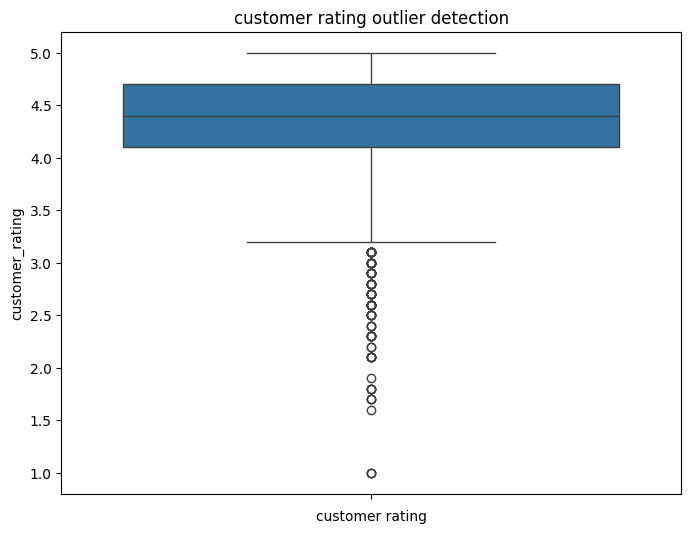

In [1048]:
plt.figure(figsize=(8,6))
sns.boxplot(data=data['customer_rating'])
plt.title('customer rating outlier detection')
plt.xlabel('customer rating')
plt.show()

In [1049]:
Q1=data['customer_rating'].quantile(0.25)
Q3=data['customer_rating'].quantile(0.75)

IQR=Q3-Q1

upper_bound=Q3+1.5*IQR
lower_bound=Q1-1.5*IQR

print('Q1:',Q1)
print('Q3:',Q3)
print('IQR:',IQR)
print('upper_bound:',upper_bound)
print('lower_bound:',lower_bound)

Q1: 4.1
Q3: 4.7
IQR: 0.6000000000000005
upper_bound: 5.600000000000001
lower_bound: 3.199999999999999


In [1050]:
rating_outlier=data[data['customer_rating']<lower_bound]

In [1051]:
rating_outlier[['customer_id','customer_rating','delivery_time_min','city','membership']].head(15)

,customer_id,customer_rating,delivery_time_min,city,membership
66,QB100066,2.7,32.5,Hyderabad,Silver
70,QB100070,1.7,51.3,Delhi,Basic
81,QB100081,2.2,15.9,Bengaluru,Basic
100,QB100100,2.6,41.0,Nagpur,Basic
122,QB100122,2.6,25.3,Mumbai,Basic
155,QB100155,2.9,50.3,Pune,Basic
178,QB100178,1.6,32.1,Indore,Platinum
188,QB100188,2.7,33.8,Jaipur,Basic
191,QB100191,3.1,20.9,Delhi,Basic
198,QB100198,3.1,18.4,Delhi,Basic


In [1052]:
# Notice that not all customers with low ratings experienced long delivery times.
# This means customer dissatisfaction may be influenced by other factors too, such as food quality, packaging, order accuracy,
# or customer service.

orders_last_12m outlier detection

In [1053]:
data['orders_last_12m'].describe()

,orders_last_12m
count,2000.00000
mean,34.89650
std,49.27424
min,5.00000
25%,17.00000
50%,24.00000
75%,32.00000
max,400.00000


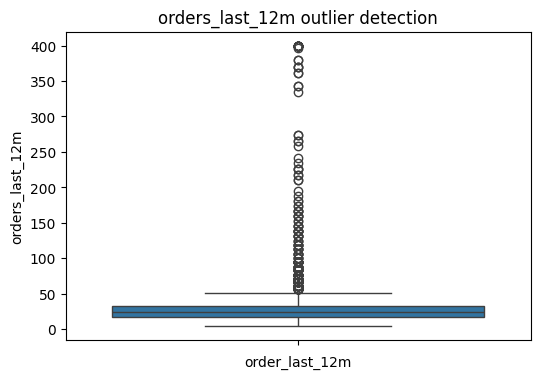

In [1054]:
plt.figure(figsize=(6,4))
sns.boxplot(data=data['orders_last_12m'])
plt.title('orders_last_12m outlier detection')
plt.xlabel('order_last_12m')
plt.show()

In [1055]:
Q1=data['orders_last_12m'].quantile(0.25)
Q3=data['orders_last_12m'].quantile(0.75)

IQR=Q3-Q1

upper_bound=Q3+1.5*IQR
lower_bound=Q1-1.5*IQR




In [1056]:
print('Q1:',Q1)
print('Q3:',Q3)
print('IQR:',IQR)
print('upper bound:',upper_bound)
print('lower bound:',lower_bound)

Q1: 17.0
Q3: 32.0
IQR: 15.0
upper bound: 54.5
lower bound: -5.5


In [1057]:
orders_last_12m_outerliers=data[data['orders_last_12m']>upper_bound]
print("number of potential outliers:",len(orders_last_12m_outerliers))
orders_last_12m_outerliers[['customer_id','orders_last_12m','annual_spend','avg_order_value','membership']].head()



number of potential outliers: 231


,customer_id,orders_last_12m,annual_spend,avg_order_value,membership
3,QB100003,379,90202.0,303.0,Basic
13,QB100013,94,14026.0,183.0,Basic
18,QB100018,77,41722.0,434.0,Platinum
19,QB100019,66,21853.0,383.0,Basic
22,QB100022,400,100747.0,278.0,Basic


In [1058]:
orders_last_12m_outerliers['avg_orders_per_month']=(orders_last_12m_outerliers['orders_last_12m']/12)
orders_last_12m_outerliers[['customer_id','orders_last_12m','avg_orders_per_month','annual_spend','membership']].sort_values('orders_last_12m',ascending=False).head()

,customer_id,orders_last_12m,avg_orders_per_month,annual_spend,membership
22,QB100022,400,33.333333,100747.0,Basic
88,QB100088,400,33.333333,75020.0,Silver
74,QB100074,400,33.333333,138256.0,Basic
198,QB100198,400,33.333333,195694.0,Basic
236,QB100236,400,33.333333,855443.0,Basic


In [1059]:
data['orders_last_12m'].describe()

,orders_last_12m
count,2000.00000
mean,34.89650
std,49.27424
min,5.00000
25%,17.00000
50%,24.00000
75%,32.00000
max,400.00000


In [1060]:
data['orders_last_12m'].value_counts().head(10)

,count
orders_last_12m,
17,366
20,292
24,273
13,221
28,162
32,132
10,92
37,73
41,64


In [1061]:
# These repeated values suggest that many customers have order counts clustered around particular values.

In [1062]:
data[data['orders_last_12m']==400][['customer_id','orders_last_12m','annual_spend','avg_order_value','membership']]

,customer_id,orders_last_12m,annual_spend,avg_order_value,membership
22,QB100022,400,100747.0,278.0,Basic
74,QB100074,400,138256.0,391.0,Basic
88,QB100088,400,75020.0,197.0,Silver
198,QB100198,400,195694.0,540.0,Basic
236,QB100236,400,855443.0,325.0,Basic
319,QB100319,400,507406.0,993.0,Platinum
371,QB100371,400,185908.0,533.0,Basic
420,QB100420,400,120851.0,368.0,Basic
436,QB100436,400,148588.0,371.0,Gold
1062,QB101062,400,67742.0,193.0,Basic


In [1063]:
# 231 potential outliers: Unusually high order counts that may represent genuine frequent customers.
# 14 customers with exactly 400 orders: A repeated maximum that needs further validation.

outlier treatment annual_spend

In [1064]:
data['annual_spend'].describe()

,annual_spend
count,2000.000000
mean,12995.852000
std,30336.382856
min,523.000000
25%,4085.750000
50%,7142.000000
75%,12781.250000
max,855443.000000


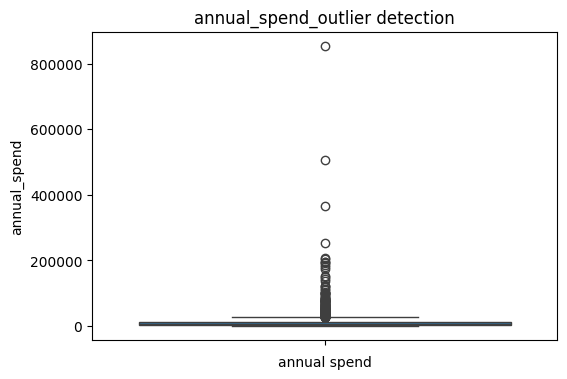

In [1065]:
plt.figure(figsize=(6,4))
sns.boxplot(data=data['annual_spend'])
plt.title('annual_spend_outlier detection')
plt.xlabel('annual spend')
plt.show()

In [1066]:
Q1=data['annual_spend'].quantile(0.25)
Q3=data['annual_spend'].quantile(0.75)

IQR=Q3-Q1

upper_bound=Q3+1.5*IQR
lower_bound=Q1-1.5*IQR


In [1067]:
print('Q1:',Q1)
print('Q3:',Q3)
print('IQR:',IQR)
print('upper_bound:',upper_bound)
print('lower_bound:',lower_bound)

Q1: 4085.75
Q3: 12781.25
IQR: 8695.5
upper_bound: 25824.5
lower_bound: -8957.5


In [1068]:
spend_outlier=data[data['annual_spend']>upper_bound]
spend_outlier[['customer_id','annual_spend','orders_last_12m','avg_order_value','membership','city']].sort_values('annual_spend',ascending=False)

,customer_id,annual_spend,orders_last_12m,avg_order_value,membership,city
236,QB100236,855443.0,400,325.0,Basic,Hyderabad
319,QB100319,507406.0,400,993.0,Platinum,Nagpur
687,QB100687,364740.0,334,1024.0,Silver,Kochi
1686,QB101686,251922.0,397,715.0,Basic,Hyderabad
1830,QB101830,207118.0,370,666.0,Basic,Hyderabad
...,...,...,...,...,...,...
1827,QB101827,26316.0,88,288.0,Silver,Hyderabad
703,QB100703,26304.0,32,625.0,Platinum,Indore
1120,QB101120,26216.0,61,424.0,Silver,Pune
735,QB100735,26167.0,46,525.0,Silver,Jaipur


In [1069]:
# # let's check the estimated annaul spend.
# spend_outlier=spend_outlier.copy()

# spend_outlier['estimated_annual_spend']=spend_outlier['avg_order_value']*spend_outlier['orders_last_12m']
# spend_outlier['difference_pct'] = (abs(spend_outlier['estimated_annual_spend'] -spend_outlier['annual_spend']) / spend_outlier['annual_spend']) * 100

# spend_outlier.sort_values('estimated_annual_pct',ascending=False)[['customer_id','avg_order_value','orders_last_12m','estimated_annual_spend','annual_spend','estimated_annual_pct']].head(10)



spend_outlier['difference_pct'] = np.where(
    spend_outlier['annual_spend'] != 0,
    abs(
        spend_outlier['estimated_annual_spend'] -
        spend_outlier['annual_spend']
    ) / spend_outlier['annual_spend'] * 100,
    np.nan
)

In [1070]:
# Variable	Decision:
# Age	:                   Corrected invalid ages; retained plausible high ages
# Delivery time	:         Retained extreme delays for operational investigation
# Average order value :	  Retained 106 potential outliers; four suspicious extreme values were imputed
# Customer rating :	      Retained low ratings as genuine feedback
# Orders last 12 months :	Retained potential outliers; flagged 14 customers with exactly 400 orders
# Annual spend :	        Retained high-spending customers; flagged possible inconsistencies

Task 3: Distribution Shapes with KDE Plots

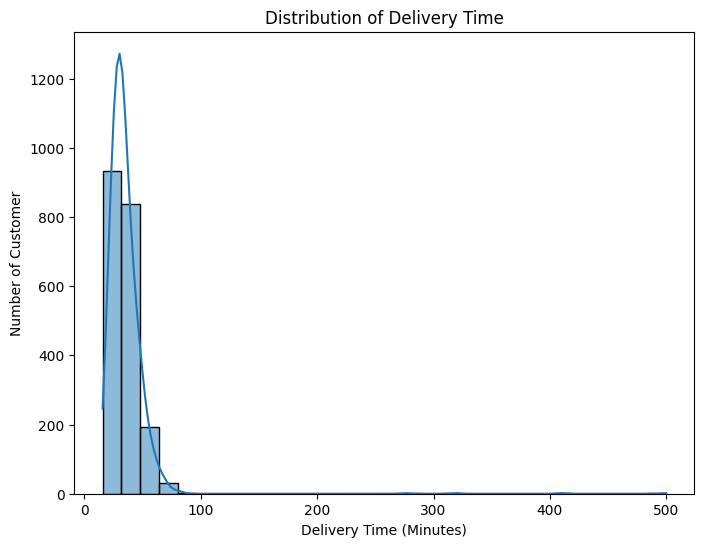

In [1071]:
plt.figure(figsize=(8,6))
sns.histplot(data=data,x='delivery_time_min',kde=True,bins=30)
plt.title('Distribution of Delivery Time')
plt.xlabel('Delivery Time (Minutes)')
plt.ylabel('Number of Customer')
plt.show()

In [1072]:
# Observation 1 — Most deliveries are concentrated between approximately 20 and 50 minutes.
# This is where the majority of customers fall.

# Observation 2 — The distribution has a long tail towards the right.
# A small number of deliveries take considerably longer, extending up to 500 minutes.

# Observation 3 — The distribution is right-skewed (positively skewed).
# The extreme delivery times pull the distribution towards the right.

In [1073]:
# Your statistics support this observation:
# - Median delivery time: 32.25 minutes.
# - Mean delivery time: approximately 34.88 minutes.
# - Maximum delivery time: 500 minutes.
# Here mean is higher than median and this is because of extreme value which pull the mean higher

In [1074]:
# Business insight: Most customers receive their orders within a relatively short period, but a small number experience significant
# delivery delays. QuickBite should investigate these delayed orders to improve delivery operations.

In [1075]:
data.columns

Index(['customer_id', 'signup_date', 'city', 'city_tier', 'gender',
       'device_type', 'acquisition_channel', 'age', 'tenure_months',
       'app_sessions_per_month', 'delivery_time_min', 'avg_order_value',
       'customer_rating', 'discount_used_pct', 'days_since_last_order',
       'membership', 'orders_last_12m', 'annual_spend',
       'estimated_annual_spend'],
      dtype='object')

Average Order Value Distribution

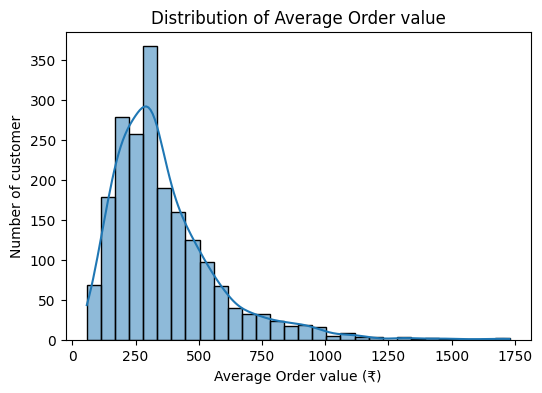

In [1076]:
plt.figure(figsize=(6,4))
sns.histplot(data=data,x='avg_order_value',kde=True,bins=30)
plt.title('Distribution of Average Order value')
plt.xlabel('Average Order value (₹)')
plt.ylabel('Number of customer')
plt.show()


In [1077]:
# Concentration: Most customers have an average order value between approximately ₹150 and ₹500.
# Long right tail: A smaller number of customers have higher order values, extending towards ₹1,700.
# Positive skewness: The distribution stretches further towards the right than the left.

In [1078]:
print("Mean:", data['avg_order_value'].mean())
print("Median:", data['avg_order_value'].median())
print("Mode:", data['avg_order_value'].mode()[0])
print("Skewness:", data['avg_order_value'].skew())

Mean: 364.6095
Median: 316.0
Mode: 325.0
Skewness: 1.8291240328124119


In [1079]:
# Bussines Insight
# Most QuickBite customers place orders of relatively moderate value, while a smaller group places more expensive orders.

In [1080]:
# Most customers spend around ₹316–₹325 per order, but some customers place significantly more expensive orders,
# increasing the average to ₹364.61.

Customer Rating Distribution

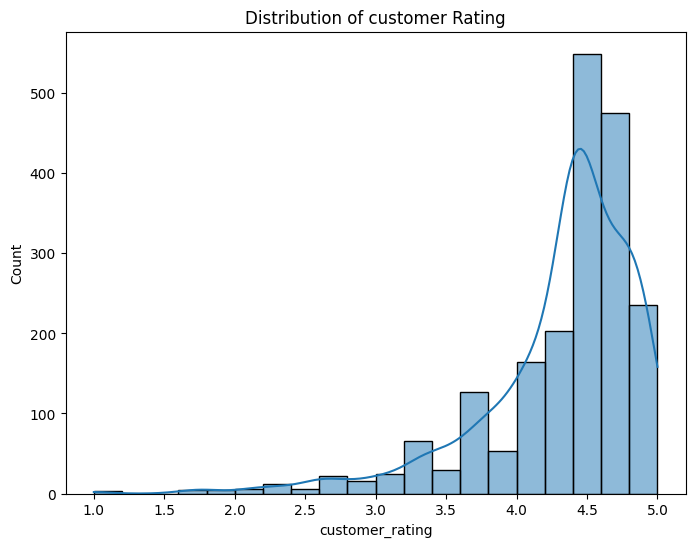

In [1081]:
plt.figure(figsize=(8,6))
sns.histplot(data=data,x='customer_rating',kde=True,bins=20)
plt.title('Distribution of customer Rating')
plt.xlabel('customer_rating')
plt.show()


In [1082]:
print("Mean:", data['customer_rating'].mean())
print("Median:", data['customer_rating'].median())
print("Mode:", data['customer_rating'].mode()[0])
print("Skewness:", data['customer_rating'].skew())

Mean: 4.3079
Median: 4.4
Mode: 4.4
Skewness: -1.8194680411777864


In [1083]:
# Most customers have given ratings between 4.3 and 4.9.
# The highest concentration of ratings is around 4.5.
# Very few customers have given ratings below 3.
# The distribution is negatively skewed (left-skewed) because the tail extends towards lower ratings.
# Overall, customer ratings appear quite positive.

In [1084]:
# Business insight Customers appear generally satisfied with the products or services,
# as most ratings are concentrated near 4.5 and above.

Anuual spend Distribution

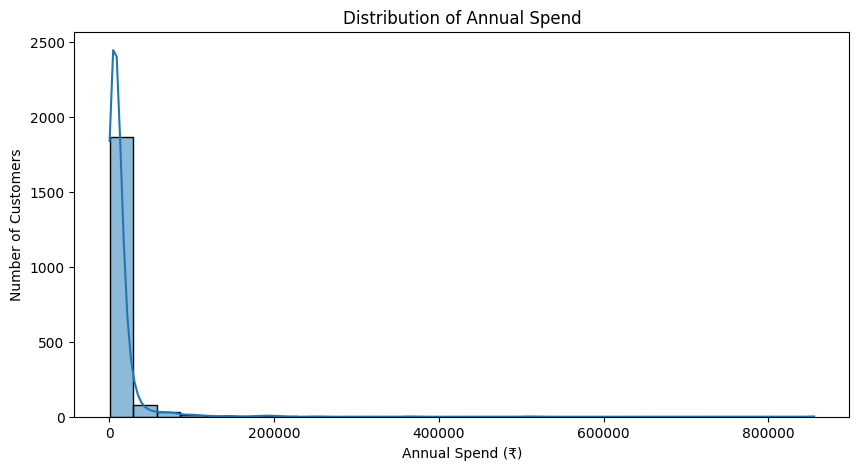

In [1085]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=data,
    x='annual_spend',
    kde=True,
    bins=30
)

plt.title('Distribution of Annual Spend')
plt.xlabel('Annual Spend (₹)')
plt.ylabel('Number of Customers')

plt.show()

In [1086]:
# Most customers have relatively low annual spending.
# A small number of customers have very high annual spending.
# The distribution has a long tail towards the right.
# Some customers have annual spending approaching ₹8,50,000.
# These extreme values may be genuine high-value customers or potential outliers.

In [1087]:
print("Mean:", data['annual_spend'].mean())
print("Median:", data['annual_spend'].median())
print("Mode:", data['annual_spend'].mode()[0])
print("Skewness:", data['annual_spend'].skew())

Mean: 12995.852
Median: 7142.0
Mode: 2916.0
Skewness: 15.238484519499103


In [1088]:
# The average annual spend is approximately ₹12,996, whereas the median is only ₹7,142.

In [1089]:
data.columns

Index(['customer_id', 'signup_date', 'city', 'city_tier', 'gender',
       'device_type', 'acquisition_channel', 'age', 'tenure_months',
       'app_sessions_per_month', 'delivery_time_min', 'avg_order_value',
       'customer_rating', 'discount_used_pct', 'days_since_last_order',
       'membership', 'orders_last_12m', 'annual_spend',
       'estimated_annual_spend'],
      dtype='object')

Age Distribution

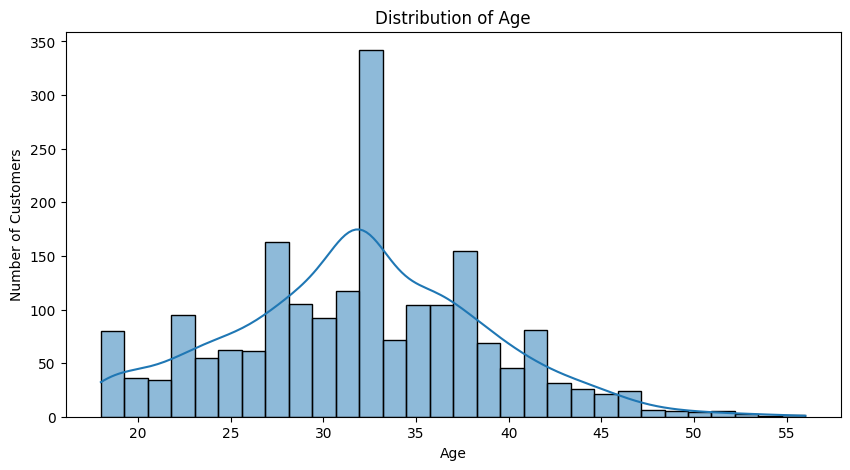

In [1090]:
data.loc[245, 'age'] = data.loc[data.index != 245, 'age'].median()
data['age'].dtype
data['age'].isna().sum()
data['age'].apply(type).value_counts()


plt.figure(figsize=(10, 5))

sns.histplot(
    data=data,
    x='age',
    kde=True,
    bins=30
)

plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()

In [1091]:
data['age'].skew()

np.float64(0.1297682972024101)

In [1092]:
data['age'].mean(), data['age'].median()

(np.float64(31.902), np.float64(32.0))

In [1093]:
# customer base has an average age of approximately 32 years. The close relationship between the mean and
# median, along with skewness of 0.13, indicates an approximately symmetric age distribution."

Order_last_12m Distribution

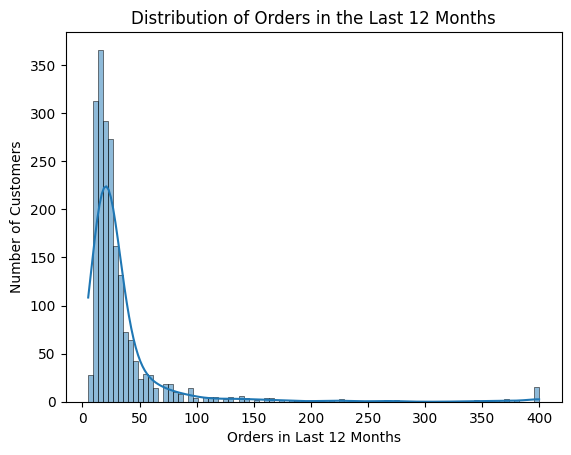

In [1094]:
sns.histplot(data=data, x='orders_last_12m', kde=True)
plt.title('Distribution of Orders in the Last 12 Months')
plt.xlabel('Orders in Last 12 Months')
plt.ylabel('Number of Customers')
plt.show()

In [1095]:
print("Mean:", data['orders_last_12m'].mean())
print("Median:", data['orders_last_12m'].median())
print("Mode:", data['orders_last_12m'].mode()[0])
print("Skewness:", data['orders_last_12m'].skew())

Mean: 34.8965
Median: 24.0
Mode: 17
Skewness: 5.310773032270558


In [1096]:
# most customers place approximately 10–35 orders annually. However, a small group of highly active
# customers places substantially more orders, creating a long right tail. These frequent customers may
# represent an important segment for customer retention and loyalty strategies.

Task 4: Relationships Between Variables

Covariance matrix ( df.cov() ) and correlation matrix ( df.corr() ) of numeric
columns. Explain in two lines why correlation is easier to interpret than covariance.

Why is correlation easier to interpret?

1. Covariance depends on the units and scale of the variables. Correlation is standardized between -1 and +1, making relationships easier to compare.




In [1097]:
# let's check the numerical columns

In [1098]:
numeric_data = data.select_dtypes(include='number')
numeric_data.columns

Index(['city_tier', 'tenure_months', 'app_sessions_per_month',
       'delivery_time_min', 'avg_order_value', 'customer_rating',
       'discount_used_pct', 'days_since_last_order', 'orders_last_12m',
       'annual_spend', 'estimated_annual_spend'],
      dtype='object')

In [1099]:
cov_matrix = numeric_data.cov()
cov_matrix

,city_tier,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,orders_last_12m,annual_spend,estimated_annual_spend
city_tier,0.596198,0.117375,0.052360,1.672140,-2.005203e+01,-0.000544,-0.156248,0.377689,9.481258e-01,-1.021972e+02,-3.755778e+01
tenure_months,0.117375,99.626390,-0.193750,1.935232,-2.797849e+01,0.107301,-0.152214,-2.991722,-7.673531e+00,-3.633604e+03,1.756012e+03
app_sessions_per_month,0.052360,-0.193750,14.277515,-1.131795,3.060976e+00,0.018546,-0.925968,1.871202,1.399696e+01,9.728321e+03,5.522150e+03
delivery_time_min,1.672140,1.935232,-1.131795,364.797663,-1.628854e+02,0.338245,-3.251319,-6.911770,-1.420244e+01,-7.620003e+03,-6.575875e+03
avg_order_value,-20.052031,-27.978489,3.060976,-162.885447,4.573956e+04,0.830125,-2.478332,-145.791291,2.151166e+02,1.636312e+06,1.677671e+06
customer_rating,-0.000544,0.107301,0.018546,0.338245,8.301250e-01,0.325951,-0.015147,-0.725249,-2.019333e-01,4.275957e+00,-9.753017e+01
discount_used_pct,-0.156248,-0.152214,-0.925968,-3.251319,-2.478332e+00,-0.015147,85.265478,-6.041903,5.876984e+00,-8.307425e+03,1.741178e+02
days_since_last_order,0.377689,-2.991722,1.871202,-6.911770,-1.457913e+02,-0.725249,-6.041903,360.377288,8.827962e+00,-9.480868e+03,-2.149259e+03
orders_last_12m,0.948126,-7.673531,13.996960,-14.202436,2.151166e+02,-0.201933,5.876984,8.827962,2.427951e+03,1.083302e+06,9.850441e+05
annual_spend,-102.197225,-3633.603721,9728.321097,-7620.003382,1.636312e+06,4.275957,-8307.425371,-9480.867708,1.083302e+06,9.202961e+08,6.017721e+08


In [1100]:
corr_matrix = numeric_data.corr()
corr_matrix

,city_tier,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,orders_last_12m,annual_spend,estimated_annual_spend
city_tier,1.000000,0.015230,0.017946,0.113384,-0.121428,-0.001235,-0.021915,0.025767,0.024920,-0.004363,-0.002043
tenure_months,0.015230,1.000000,-0.005137,0.010151,-0.013107,0.018830,-0.001652,-0.015789,-0.015602,-0.012000,0.007388
app_sessions_per_month,0.017946,-0.005137,1.000000,-0.015683,0.003788,0.008597,-0.026539,0.026086,0.075177,0.084869,0.061373
delivery_time_min,0.113384,0.010151,-0.015683,1.000000,-0.039876,0.031019,-0.018435,-0.019063,-0.015091,-0.013151,-0.014459
avg_order_value,-0.121428,-0.013107,0.003788,-0.039876,1.000000,0.006799,-0.001255,-0.035909,0.020413,0.252207,0.329426
customer_rating,-0.001235,0.018830,0.008597,0.031019,0.006799,1.000000,-0.002873,-0.066916,-0.007178,0.000247,-0.007174
discount_used_pct,-0.021915,-0.001652,-0.026539,-0.018435,-0.001255,-0.002873,1.000000,-0.034467,0.012917,-0.029656,0.000792
days_since_last_order,0.025767,-0.015789,0.026086,-0.019063,-0.035909,-0.066916,-0.034467,1.000000,0.009438,-0.016463,-0.004755
orders_last_12m,0.024920,-0.015602,0.075177,-0.015091,0.020413,-0.007178,0.012917,0.009438,1.000000,0.724713,0.839522
annual_spend,-0.004363,-0.012000,0.084869,-0.013151,0.252207,0.000247,-0.029656,-0.016463,0.724713,1.000000,0.833038


In [1101]:
# 1. Find the strongest relationship with annual_spend
# Let's focus on the annual_spend column:
# Variable.              	Correlation	                       Interpretation
# orders_last_12m	        0.7247	                           Strong positive relationship
# avg_order_value	        0.2522	                           Weak positive relationship
# app_sessions_per_month	0.0849	                           Very weak positive relationship
# customer_rating.       	0.0002	                           Almost no linear relationship
# delivery_time_min	     -0.0132	                           Almost no linear relationship
# days_since_last_order	 -0.0165	                           Almost no linear relationship
# discount_used_pct	     -0.0297	                           Almost no linear relationship

In [1102]:
analysis_numeric = numeric_data.drop(columns=['estimated_annual_spend'])

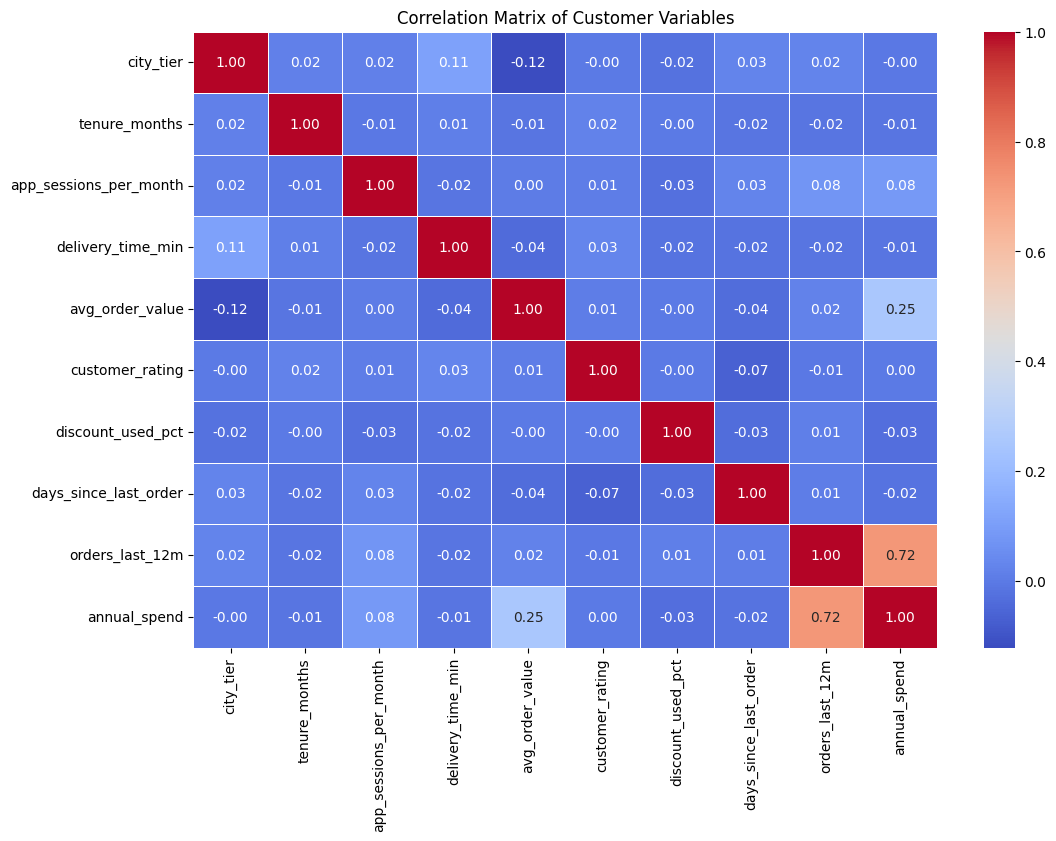

In [1103]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    analysis_numeric.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix of Customer Variables')
plt.show()

In [1104]:
# Variables	                               Correlation	               Interpretation
# Orders last 12 months ↔ Annual spend	   +0.72	                     Strong positive
# Average order value ↔ Annual spend	     +0.25	                     Weak positive
# City tier ↔ Average order value	         -0.12	                     Weak negative
# Customer rating ↔ Days since last order  -0.07	                     Very weak negative
# App sessions ↔ Annual spend	             +0.08	                     Very weak positive

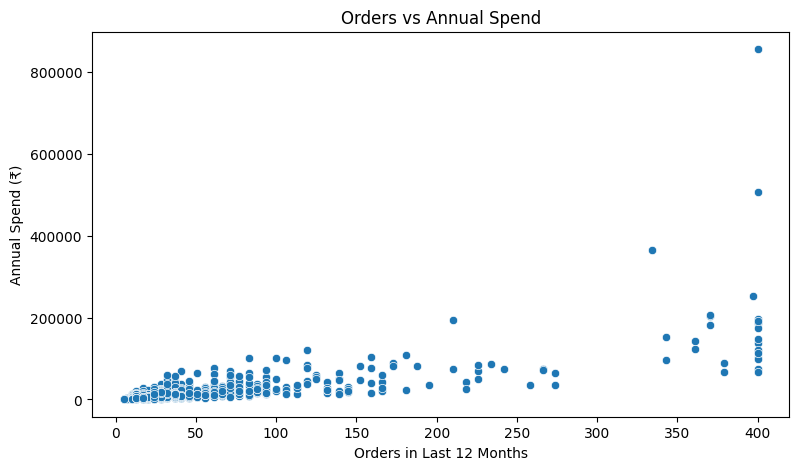

In [1105]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=data,
    x='orders_last_12m',
    y='annual_spend'
)

plt.title('Orders vs Annual Spend')
plt.xlabel('Orders in Last 12 Months')
plt.ylabel('Annual Spend (₹)')
plt.show()

In [1106]:
# 1. Positive relationship: Generally, customers who place more orders tend to have higher annual spending.
# 2. High concentration: Most customers are clustered below 100 orders and below ₹1,00,000 annual spend.
# 3. Increasing variability: As the number of orders increases, annual spending becomes more spread out.
# 4. Extreme values: Some customers have approximately 400 orders, with annual spending reaching ₹8,50,000.
# 5. Potential outliers: A few customers have exceptionally high annual spending compared with the majority.

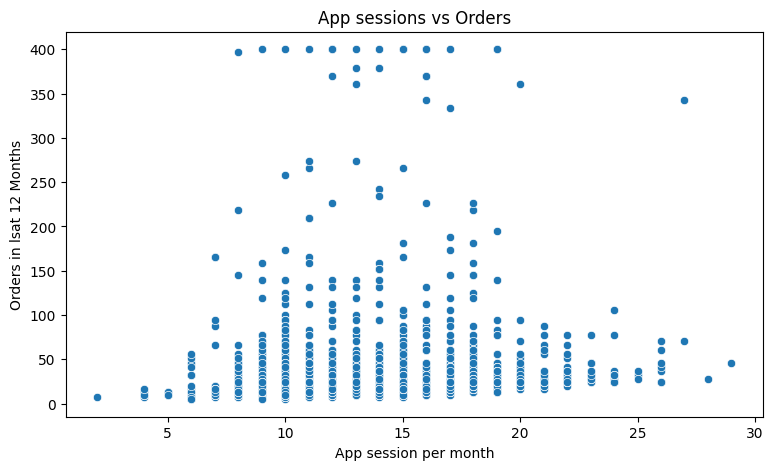

In [1107]:
plt.figure(figsize=(9,5))
sns.scatterplot(data=data,x='app_sessions_per_month',y='orders_last_12m')
plt.title('App sessions vs Orders')
plt.xlabel('App session per month')
plt.ylabel('Orders in lsat 12 Months')
plt.show()


In [1108]:
# 1. No clear linear pattern: As app sessions increase, orders do not consistently increase or decrease.
# 2. High concentration: Most customers have approximately 8–20 app sessions and fewer than 100 orders.
# 3. Scattered points: Customers with similar app sessions have significantly different order counts.
# 4. Extreme values: A few customers have around 350–400 orders despite having varying app session counts.

In [1109]:
data.columns

Index(['customer_id', 'signup_date', 'city', 'city_tier', 'gender',
       'device_type', 'acquisition_channel', 'age', 'tenure_months',
       'app_sessions_per_month', 'delivery_time_min', 'avg_order_value',
       'customer_rating', 'discount_used_pct', 'days_since_last_order',
       'membership', 'orders_last_12m', 'annual_spend',
       'estimated_annual_spend'],
      dtype='object')

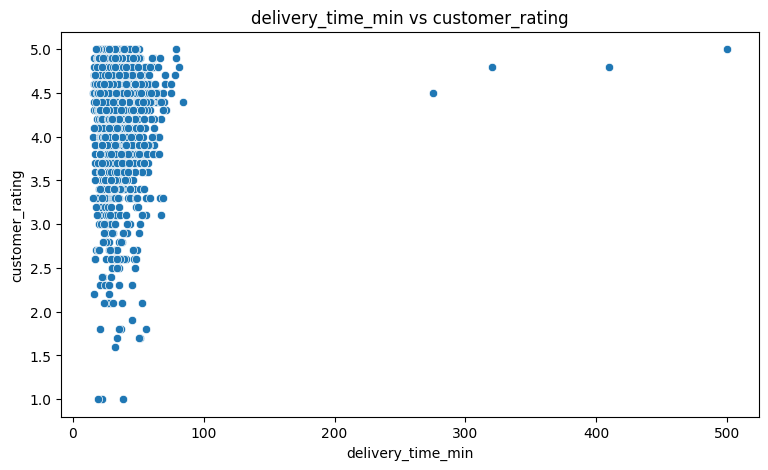

In [1110]:
plt.figure(figsize=(9,5))
sns.scatterplot(data=data,x='delivery_time_min',y='customer_rating')
plt.title("delivery_time_min vs customer_rating")
plt.xlabel('delivery_time_min')
plt.ylabel('customer_rating')
plt.show()

In [1111]:
# 1. Ratings are generally high
#    Most customers have given ratings between 3.5 and 5.0, indicating generally positive customer feedback.
# 2. No strong downward trend is visible
#    As delivery time increases, customer ratings do not consistently decrease. The points are widely scattered.
# 3. Most delivery times are concentrated
#    Most observations fall between approximately 15 and 80 minutes.
# 4. Extreme delivery times
#    A few observations have delivery times above 250 minutes, including one around 500 minutes. These should be investigated as potential outliers or data-quality issues.
# 5. Longer delivery does not always mean lower ratings
#    Interestingly, some customers with very long delivery times have still given ratings between 4.5 and 5.0.

Line plot: number of new signups per month (use signup_date ), and average
delivery_time_min by signup month.

In [1112]:
monthly_signups = (
    data.groupby(data['signup_date'].dt.to_period('M'))
    .size()
)

monthly_signups.head()

,0
signup_date,
2023-01,54
2023-02,62
2023-03,53
2023-04,65
2023-05,56


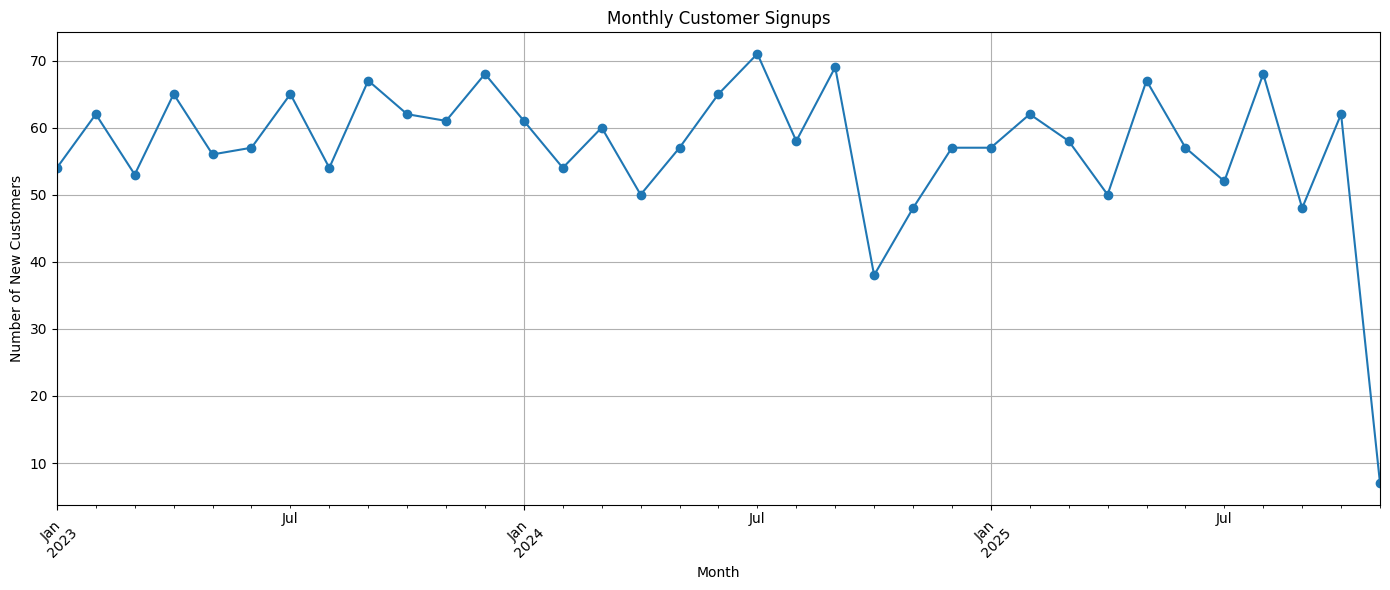

In [1113]:
plt.figure(figsize=(14, 6))

monthly_signups.plot(kind='line', marker='o')

plt.title('Monthly Customer Signups')
plt.xlabel('Month')
plt.ylabel('Number of New Customers')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [1114]:

# 1. Overall signup trend: Customer signups remain relatively stable from January 2023 through October 2025, generally fluctuating between
#    50 and 70 customers per month. There is no clear long-term upward or downward trend.
# 2. Noticeable increases: Signups increased significantly around June–July 2023, reaching approximately 68 and 71 customers. Another noticeable
#    increase occurred in October 2024, when signups rose to around 69.
# 3. Noticeable decreases: A sharp decline occurred in October 2024, when signups dropped from approximately 69 in September to 38. Signups
#    recovered gradually over the following months.
# 4. Consistency and variability: Monthly signups are moderately variable, with most months recording between 50 and 70 new customers.
#    This suggests a relatively consistent customer acquisition pattern despite some fluctuations.
# 5. Unusual pattern requiring investigation: Signups dropped dramatically to approximately 7 in October 2025, the lowest value on the chart.
#    This unusual decline should be investigated to determine whether it resulted from a reporting issue, missing data, or an actual decrease in customer acquisition.

In [1115]:
monthly_delivery = (
    data.groupby(data['signup_date'].dt.to_period('M'))['delivery_time_min']
    .mean()
)

monthly_delivery

,delivery_time_min
signup_date,
2023-01,32.594444
2023-02,34.346774
2023-03,35.011321
2023-04,39.962308
2023-05,35.734821
2023-06,40.866667
2023-07,36.227692
2023-08,33.506481
2023-09,33.777612


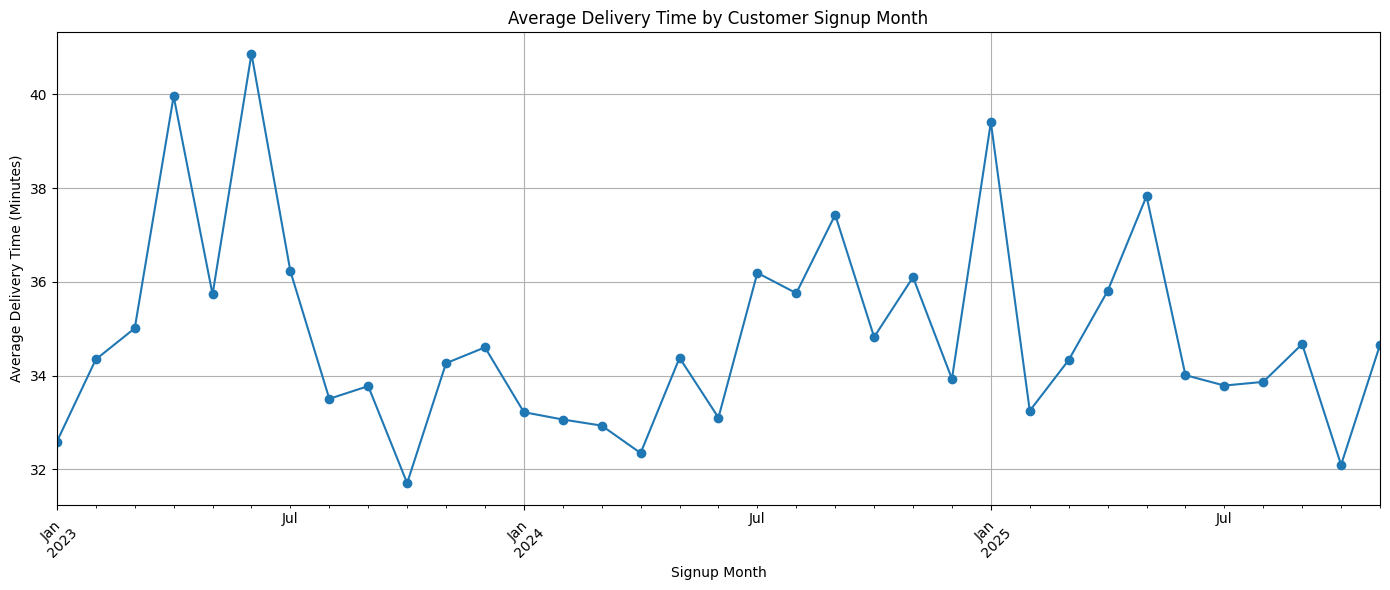

In [1116]:
plt.figure(figsize=(14, 6))

monthly_delivery.plot(kind='line', marker='o')

plt.title('Average Delivery Time by Customer Signup Month')
plt.xlabel('Signup Month')
plt.ylabel('Average Delivery Time (Minutes)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [1117]:
# 1. Overall pattern: Average delivery times fluctuate throughout the period, generally ranging between 32 and 41 minutes.
#    Most monthly averages fall between 33 and 37 minutes.
# 2. Unusually high averages: Noticeable peaks occur in April 2023 (approximately 40 minutes), June 2023 (41 minutes, the highest),
#    and January 2025 (approximately 39.4 minutes). These months may indicate delivery delays that require investigation.
# 3. Unusually low averages: Delivery times are lowest in October 2023 (approximately 31.7 minutes), May 2024 (approximately 32.3 minutes),
#    and October 2025 (approximately 32.1 minutes). These months show comparatively faster deliveries.
# 4. Stability and variability: Delivery times are moderately variable rather than completely stable. There are several sharp month-to-month
#    increases and decreases, particularly during 2023 and early 2025.
# 5. Improvement or deterioration over time: There is no clear long-term deterioration or consistent improvement. Delivery times generally remain
#   within a similar range, although the lower averages toward late 2025 may suggest some improvement in delivery performance.

Box plots by category: annual_spend by membership , delivery_time_min by
city_tier .

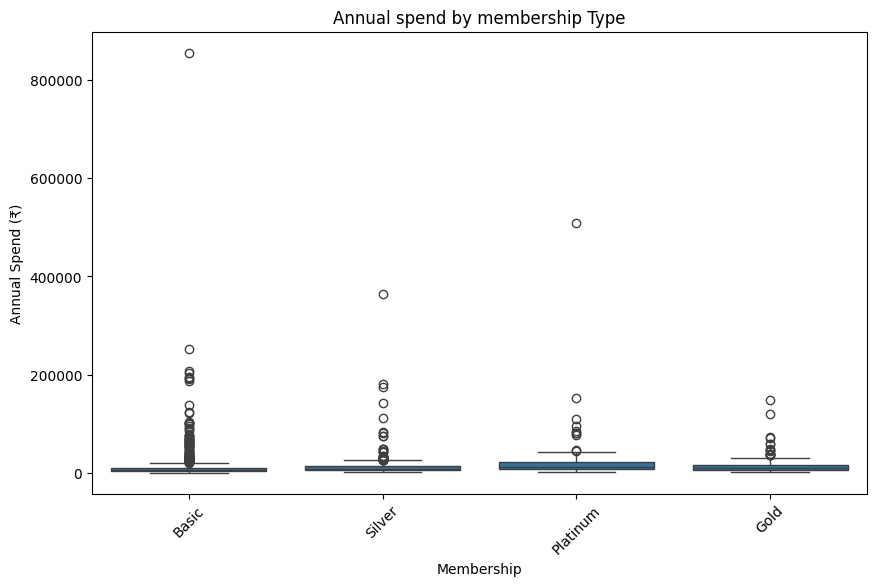

In [1118]:
plt.figure(figsize=(10,6))
sns.boxplot(data=data,x='membership',y='annual_spend')

plt.title('Annual spend by membership Type')
plt.xlabel('Membership')
plt.ylabel('Annual Spend (₹)')
plt.xticks(rotation=45)
plt.show()

In [1119]:
# 1. Highest median spending: Platinum membership appears to have the highest median annual spending, followed by Gold, Silver, and Basic.
# 2. Widest spread: Platinum membership appears to have a relatively wide spread in spending, indicating greater variation among its customers.
#    Basic also shows substantial variability due to numerous high-spending outliers.
# 3. Extreme high-spending customers: Yes. All four membership types have extreme high-spending customers. Notable outliers include:
#    Basic: approximately ₹855,000.
#    Platinum: approximately ₹510,000.
#    Silver: approximately ₹365,000.
#    Gold: approximately ₹150,000.
# 4. Spending by membership level: Spending generally appears to increase with membership level, particularly from Basic to Platinum. However,
#    the pattern is not perfectly consistent, and there is considerable overlap between membership groups.

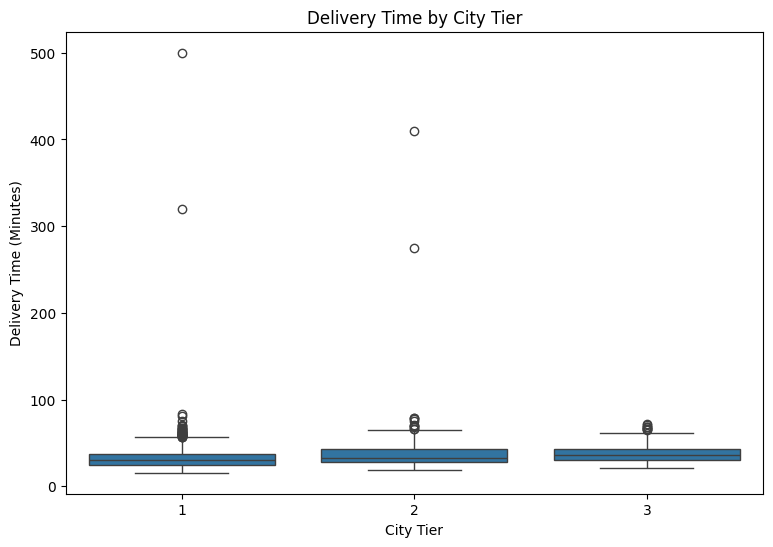

In [1120]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=data,
    x='city_tier',
    y='delivery_time_min'
)

plt.title('Delivery Time by City Tier')
plt.xlabel('City Tier')
plt.ylabel('Delivery Time (Minutes)')
plt.show()

In [1121]:
# Tier 1: Relatively low median delivery time but has some severe delays.
# Tier 2: Slightly higher median and greater variability, with significant extreme delays.
# Tier 3: Highest median delivery time but more consistent delivery performance and fewer extreme delays.

Answer: which variable has the strongest relationship with      annual_spend ? Does
correlation prove causation?
  
  Orders last 12 months ↔ Annual spend
  Correlation only tells us that two variables move together. It does not establish that one variable directly causes the other.

Task 5: Encoding Categorical Variables

In [1122]:
membership_map={'Basic':0,'Silver':1,'Gold':2,'Platinum':3}
data['membership_encoded']=data['membership'].map(membership_map)

data[['membership','membership_encoded']].head(10)

,membership,membership_encoded
0,Basic,0
1,Basic,0
2,Basic,0
3,Basic,0
4,Basic,0
5,Basic,0
6,Silver,1
7,Basic,0
8,Basic,0
9,Silver,1


In [1123]:
data.columns

Index(['customer_id', 'signup_date', 'city', 'city_tier', 'gender',
       'device_type', 'acquisition_channel', 'age', 'tenure_months',
       'app_sessions_per_month', 'delivery_time_min', 'avg_order_value',
       'customer_rating', 'discount_used_pct', 'days_since_last_order',
       'membership', 'orders_last_12m', 'annual_spend',
       'estimated_annual_spend', 'membership_encoded'],
      dtype='object')

In [1124]:
data['device_type'].value_counts()

,count
device_type,
Android,1171
iOS,655
Web,174


In [1125]:
device_encoded=pd.get_dummies(data['device_type'],prefix='device',dtype=int)
data=pd.concat([data,device_encoded],axis=1)
data[['device_type','device_Android','device_iOS','device_Web']].head(10)

,device_type,device_Android,device_iOS,device_Web
0,Android,1,0,0
1,iOS,0,1,0
2,iOS,0,1,0
3,Android,1,0,0
4,Android,1,0,0
5,Android,1,0,0
6,iOS,0,1,0
7,iOS,0,1,0
8,iOS,0,1,0
9,Android,1,0,0


In [1126]:
device_encoded = pd.get_dummies(
    data['device_type'],
    prefix='device',
    drop_first=True,
    dtype=int
)

device_encoded.head(10)

,device_Web,device_iOS
0,0,0
1,0,1
2,0,1
3,0,0
4,0,0
5,0,0
6,0,1
7,0,1
8,0,1
9,0,0


In [1127]:
data['acquisition_channel'].value_counts()

,count
acquisition_channel,
Organic,592
Paid Social,492
Referral,418
Search Ads,279
Influencer,219


In [1128]:
acquisition_channel_encoded=pd.get_dummies(data['acquisition_channel'],prefix='channel',dtype=int)
data=pd.concat([data,acquisition_channel_encoded],axis=1)

In [1129]:
acquisition_channel_encoded.head(10)

,channel_Influencer,channel_Organic,channel_Paid Social,channel_Referral,channel_Search Ads
0,0,0,0,1,0
1,1,0,0,0,0
2,0,0,0,1,0
3,0,0,1,0,0
4,0,0,0,0,1
5,0,0,1,0,0
6,0,0,0,0,1
7,0,1,0,0,0
8,0,1,0,0,0
9,0,0,1,0,0


In [1130]:
data['acquisition_channel'].value_counts()

,count
acquisition_channel,
Organic,592
Paid Social,492
Referral,418
Search Ads,279
Influencer,219


In [1131]:
data['acquisition_channel'].unique()

array(['Referral', 'Influencer', 'Paid Social', 'Search Ads', 'Organic'],
      dtype=object)

In [1132]:
acquisition_channel_encoded=pd.get_dummies(data['acquisition_channel'],prefix='channel',drop_first=True,dtype=int)
acquisition_channel_encoded.head(10)

,channel_Organic,channel_Paid Social,channel_Referral,channel_Search Ads
0,0,0,1,0
1,0,0,0,0
2,0,0,1,0
3,0,1,0,0
4,0,0,0,1
5,0,1,0,0
6,0,0,0,1
7,1,0,0,0
8,1,0,0,0
9,0,1,0,0


In [1133]:
# Applying the Target Encoding for city

In [1134]:
city_mean=data.groupby('city')['annual_spend'].mean()

In [1135]:
city_mean

,annual_spend
city,
Bengaluru,12004.006803
Delhi,12152.446667
Hyderabad,18300.340249
Indore,10732.646259
Jaipur,10410.643357
Kochi,15739.561905
Lucknow,13939.898649
Mumbai,12020.796875
Nagpur,15515.557692


In [1136]:
data['city_encoded']=data['city'].map(city_mean)
data[['city','city_encoded','annual_spend']].head(10)

,city,city_encoded,annual_spend
0,Lucknow,13939.898649,8675.0
1,Bengaluru,12004.006803,7896.0
2,Indore,10732.646259,1826.0
3,Jaipur,10410.643357,90202.0
4,Mumbai,12020.796875,2773.0
5,Kochi,15739.561905,2604.0
6,Lucknow,13939.898649,9594.0
7,Lucknow,13939.898649,6532.0
8,Mumbai,12020.796875,3207.0
9,Bengaluru,12004.006803,2895.0


Task 6: Central Tendency and Percentiles

In [1137]:
columns = ['age', 'orders_last_12m', 'annual_spend','delivery_time_min']

for col in columns:
    print(f"\n{col}")
    print("Mean:", data[col].mean())
    print("Median:", data[col].median())
    print("Mode:", data[col].mode()[0])


age
Mean: 31.902
Median: 32.0
Mode: 32.0

orders_last_12m
Mean: 34.8965
Median: 24.0
Mode: 17

annual_spend
Mean: 12995.852
Median: 7142.0
Mode: 2916.0

delivery_time_min
Mean: 34.881550000000004
Median: 32.25
Mode: 32.25


In [1138]:
data['membership'].mode()

,membership
0,Basic


A relatively small number of high-spending customers increase the overall average.



The mean does not represent what a typical customer spends.



QuickBite should use the median to understand typical customer spending and investigate high-value customers for retention opportunities

In [1139]:
percentiles = [0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
delivery_percentiles = data['delivery_time_min'].quantile(percentiles)
print(delivery_percentiles)

0.10    22.100
0.25    26.500
0.50    32.250
0.75    40.100
0.90    49.210
0.95    55.400
0.99    68.602
Name: delivery_time_min, dtype: float64


P10: Approximately 10% of customers receive deliveries within 22.1 minutes or less.



P25: 25% receive deliveries within 26.5 minutes or less.



P50: Half receive deliveries within 32.25 minutes or less.



P75: 75% receive deliveries within 40.1 minutes or less.



P90: 90% receive deliveries within 49.21 minutes or less.



P95: 95% receive deliveries within 55.4 minutes or less.



P99: 99% receive deliveries within 68.6 minutes or less.

In [1140]:
percentiles = [0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
delivery_percentiles = data['annual_spend'].quantile(percentiles)
print(delivery_percentiles)

0.10      2508.60
0.25      4085.75
0.50      7142.00
0.75     12781.25
0.90     22453.70
0.95     35355.25
0.99    109149.78
Name: annual_spend, dtype: float64


50% of customers spend ₹7,142 or less annually.



75% spend ₹12,781.25 or less.



90% spend ₹22,453.70 or less.



99% spend ₹1,09,149.78 or less.


Draw a box plot and annotate quartiles.

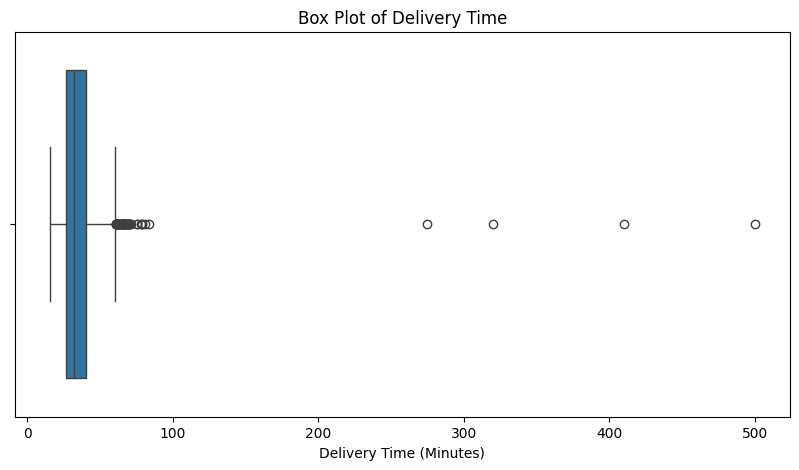

In [1141]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=data['delivery_time_min'])

plt.title('Box Plot of Delivery Time')
plt.xlabel('Delivery Time (Minutes)')

plt.show()

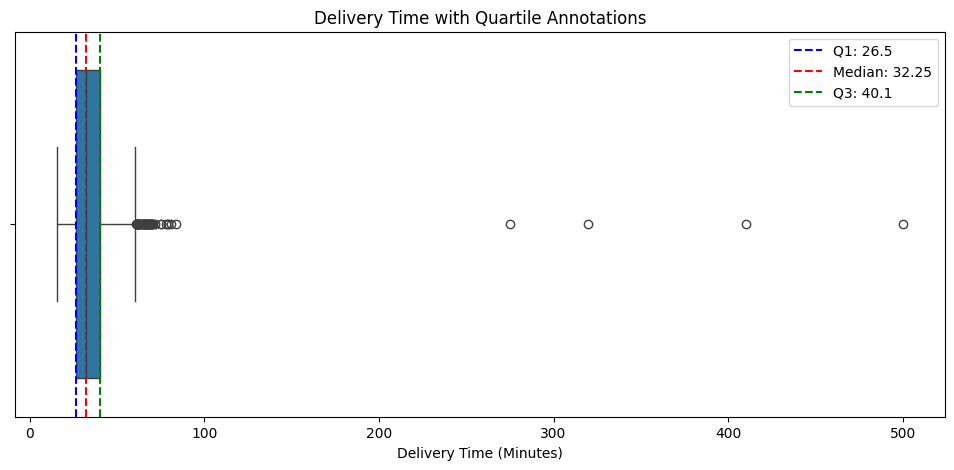

Q1: 26.5
Median: 32.25
Q3: 40.1
IQR: 13.600000000000001


In [1142]:
q1 = data['delivery_time_min'].quantile(0.25)
median = data['delivery_time_min'].median()
q3 = data['delivery_time_min'].quantile(0.75)
iqr = q3 - q1

plt.figure(figsize=(12, 5))

sns.boxplot(x=data['delivery_time_min'])

plt.axvline(q1, color='blue', linestyle='--', label=f'Q1: {q1}')
plt.axvline(median, color='red', linestyle='--', label=f'Median: {median}')
plt.axvline(q3, color='green', linestyle='--', label=f'Q3: {q3}')

plt.title('Delivery Time with Quartile Annotations')
plt.xlabel('Delivery Time (Minutes)')
plt.legend()
plt.show()

print("Q1:", q1)
print("Median:", median)
print("Q3:", q3)
print("IQR:", iqr)

1. Median: The median delivery time is approximately 33 minutes, indicating that half of the deliveries take less than this time and half take longer.

2. Quartiles (Q1 and Q3):
- Q1 (25th percentile) is approximately 27 minutes.
- Q3 (75th percentile) is approximately 40 minutes.
- The middle 50% of deliveries fall between approximately 27 and 40 minutes.
3. Interquartile Range (IQR): Approximately 13 minutes (Q3 − Q1).

4. Whiskers: Most delivery times fall approximately between 16 and 60 minutes.

5. Outliers: Several unusually long delivery times are visible, particularly around 270, 320, 410, and 500 minutes. These may represent exceptional delivery delays.

6. Distribution: The data is strongly right-skewed because a few deliveries take significantly longer than the majority.

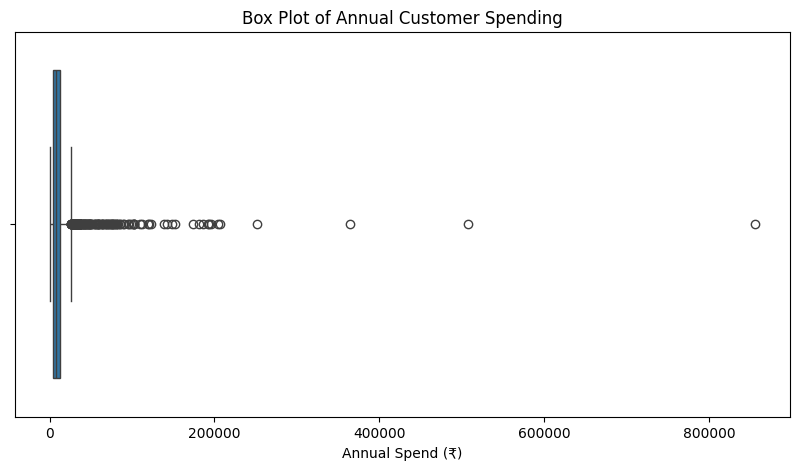

In [1143]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=data['annual_spend'])

plt.title('Box Plot of Annual Customer Spending')
plt.xlabel('Annual Spend (₹)')

plt.show()

1. Median (Q2)

The median annual spending appears to be around ₹8,000–₹10,000. This represents the typical spending level of customers.

2. Quartiles (Q1 and Q3)
- Q1 (25th percentile): Approximately ₹5,000.
- Q3 (75th percentile): Approximately ₹15,000.
- The middle 50% of customers spend within this relatively narrow range.
These are visual estimates from the plot, not exact calculated values.

3. Interquartile Range (IQR)

The IQR represents the spending range of the middle 50% of customers.
\[
IQR = Q3-Q1
\]

It appears to be approximately ₹10,000.

4. Whiskers

Most non-outlier spending values are concentrated below approximately ₹25,000.

5. Outliers

There are numerous high-spending outliers:
- Many customers spend between ₹25,000 and ₹100,000.
- Some spend between ₹100,000 and ₹200,000.
- A few extreme outliers appear around ₹250,000, ₹365,000, ₹510,000 and ₹855,000.
6. Distribution

The distribution is extremely right-skewed. Most customers spend relatively small amounts, while a small number spend exceptionally large amounts.

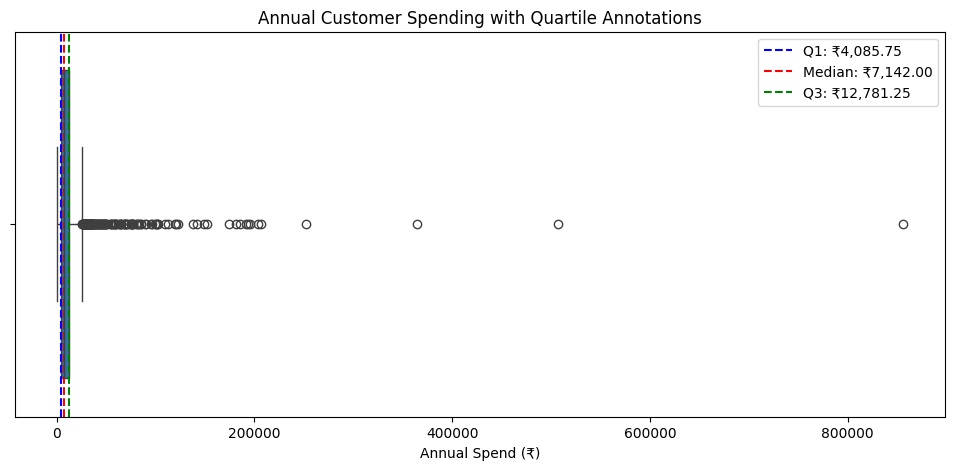

Q1: 4085.75
Median: 7142.0
Q3: 12781.25
IQR: 8695.5


In [1144]:
q1 = data['annual_spend'].quantile(0.25)
median = data['annual_spend'].median()
q3 = data['annual_spend'].quantile(0.75)
iqr = q3 - q1

plt.figure(figsize=(12, 5))

sns.boxplot(x=data['annual_spend'])

plt.axvline(q1, color='blue', linestyle='--', label=f'Q1: ₹{q1:,.2f}')
plt.axvline(median, color='red', linestyle='--', label=f'Median: ₹{median:,.2f}')
plt.axvline(q3, color='green', linestyle='--', label=f'Q3: ₹{q3:,.2f}')

plt.title('Annual Customer Spending with Quartile Annotations')
plt.xlabel('Annual Spend (₹)')
plt.legend()
plt.show()

print("Q1:", q1)
print("Median:", median)
print("Q3:", q3)
print("IQR:", iqr)

In [1145]:
p90=data['delivery_time_min'].quantile(0.90)
print("90th Percentile:", p90)

90th Percentile: 49.210000000000015


Approximately 90% of customers received their deliveries within 49.21 minutes.


Approximately 10% experienced delivery times above 49.21 minutes.

In [1146]:
p95 = data['delivery_time_min'].quantile(0.95)
print("95th Percentile:", p95)

95th Percentile: 55.4


P90: 90% of deliveries take approximately 49.21 minutes or less.



P95: 95% of deliveries take approximately 55.4 minutes or less.

49 minutes as the initial operational benchmark.

Task 7: Pareto Distribution and the 80/20 Rule

In [1147]:
# Sort customers from highest to lowest annual spend
sorted_data = data.sort_values(
    by='annual_spend',
    ascending=False
).reset_index(drop=True)

# Identify the top 20% of customers
top_20_count = int(len(sorted_data) * 0.20)

top_20_customers = sorted_data.head(top_20_count)

# Calculate revenue contribution
total_revenue = data['annual_spend'].sum()

top_20_revenue = top_20_customers['annual_spend'].sum()

top_20_percentage = (top_20_revenue / total_revenue) * 100

print("Total customers:", len(data))
print("Top 20% customer count:", top_20_count)
print("Total revenue:", round(total_revenue, 2))
print("Top 20% revenue:", round(top_20_revenue, 2))
print("Revenue contribution of top 20%:", round(top_20_percentage, 2), "%")

Total customers: 2000
Top 20% customer count: 400
Total revenue: 25991704.0
Top 20% revenue: 15754552.0
Revenue contribution of top 20%: 60.61 %


In [1148]:
sorted_data['revenue_percentage'] = (
    sorted_data['annual_spend'] / total_revenue
) * 100

sorted_data['cumulative_revenue_percentage'] = (
    sorted_data['revenue_percentage'].cumsum()
)

sorted_data['cumulative_customer_percentage'] = (
    (sorted_data.index + 1) / len(sorted_data)
) * 100

sorted_data.head(10)

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,...,device_iOS,channel_Influencer,channel_Organic,channel_Paid Social,channel_Referral,channel_Search Ads,city_encoded,revenue_percentage,cumulative_revenue_percentage,cumulative_customer_percentage
0,QB100236,2025-09-09,Hyderabad,1,Female,Android,Paid Social,36.0,13.9,15,...,0,0,0,1,0,0,18300.340249,3.291216,3.291216,0.05
1,QB100319,2023-02-14,Nagpur,3,Unknown,Android,Paid Social,31.0,45.2,19,...,0,0,0,1,0,0,15515.557692,1.952184,5.243400,0.10
2,QB100687,2023-10-27,Kochi,3,Female,Android,Referral,29.0,36.7,17,...,0,0,0,0,1,0,15739.561905,1.403294,6.646694,0.15
3,QB101686,2025-02-27,Hyderabad,1,Male,Web,Search Ads,23.0,20.4,8,...,0,0,0,0,0,1,18300.340249,0.969240,7.615934,0.20
4,QB101830,2023-12-10,Hyderabad,1,Female,Android,Organic,28.0,35.2,16,...,0,0,1,0,0,0,18300.340249,0.796862,8.412796,0.25
5,QB101162,2023-10-26,Lucknow,2,Female,Android,Organic,38.0,36.7,16,...,0,0,1,0,0,0,13939.898649,0.784027,9.196823,0.30
6,QB100198,2025-09-17,Delhi,1,Male,iOS,Referral,25.0,13.6,12,...,1,0,0,0,1,0,12152.446667,0.752909,9.949732,0.35
7,QB101167,2023-07-22,Hyderabad,1,Male,Android,Influencer,49.0,39.9,11,...,0,1,0,0,0,0,18300.340249,0.745861,10.695593,0.40
8,QB101924,2025-08-05,Delhi,1,Unknown,Android,Paid Social,36.0,15.1,13,...,0,0,0,1,0,0,12152.446667,0.737612,11.433206,0.45
9,QB100371,2023-06-26,Delhi,1,Male,Web,Search Ads,40.0,40.8,12,...,0,0,0,0,0,1,12152.446667,0.715259,12.148465,0.50


Your first 10 customers contribute approximately 12.15% of total revenue, even though they represent only 0.5% of customers.

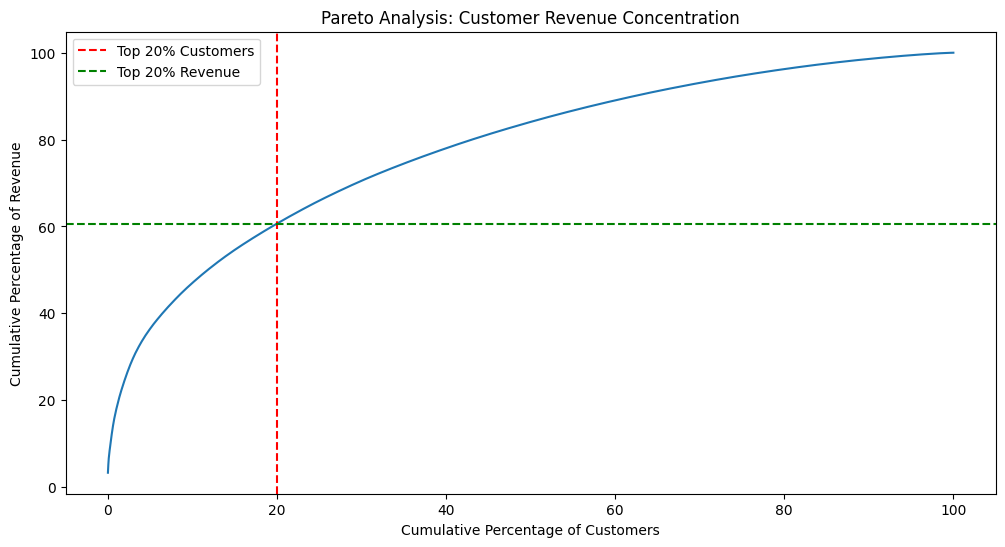

In [1149]:
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(
    sorted_data['cumulative_customer_percentage'],
    sorted_data['cumulative_revenue_percentage']
)

ax1.set_xlabel('Cumulative Percentage of Customers')
ax1.set_ylabel('Cumulative Percentage of Revenue')
ax1.set_title('Pareto Analysis: Customer Revenue Concentration')

ax1.axvline(20, linestyle='--', color='red', label='Top 20% Customers')
ax1.axhline(60.61, linestyle='--', color='green', label='Top 20% Revenue')

ax1.legend()
plt.show()

The top 20% of QuickBite's customers generate 60.61% of its total annual revenue (₹1.58 crore out of ₹2.60 crore).

Task 8: PDF and CDF

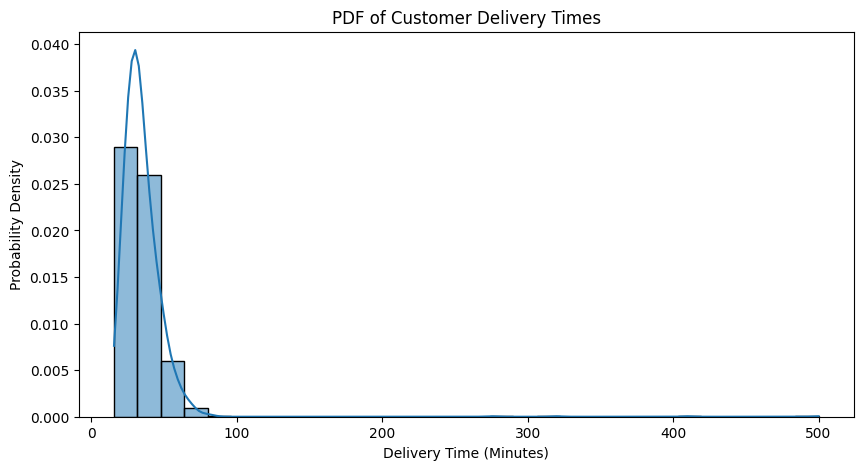

In [1150]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=data,
    x='delivery_time_min',
    stat='density',
    kde=True,
    bins=30
)

plt.title('PDF of Customer Delivery Times')
plt.xlabel('Delivery Time (Minutes)')
plt.ylabel('Probability Density')

plt.show()

The PDF shows that QuickBite generally completes deliveries within a reasonable time, with most deliveries concentrated around 25–35 minutes. However, the long right tail indicates occasional extreme delays.

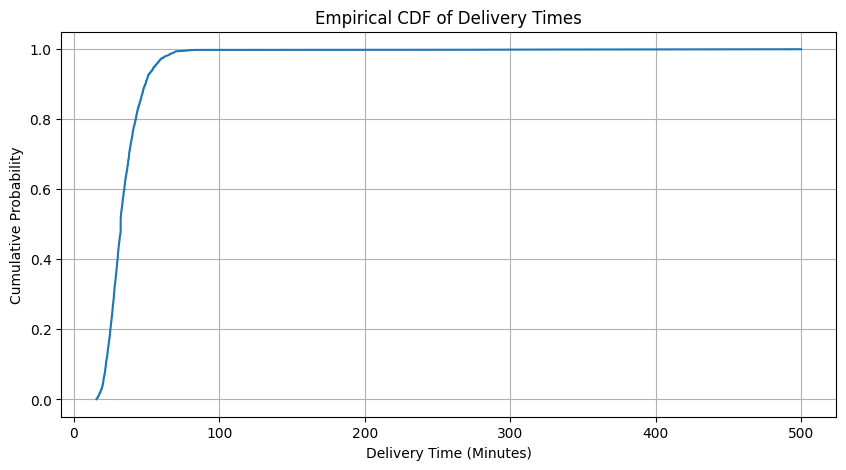

In [1151]:
delivery_sorted = np.sort(data['delivery_time_min'])

cumulative_probability = (
    np.arange(1, len(delivery_sorted) + 1)
    / len(delivery_sorted)
)

plt.figure(figsize=(10, 5))

plt.plot(delivery_sorted, cumulative_probability)

plt.title('Empirical CDF of Delivery Times')
plt.xlabel('Delivery Time (Minutes)')
plt.ylabel('Cumulative Probability')

plt.grid()
plt.show()

QuickBite completes approximately half of its deliveries within 30 minutes and around 95% within 55–60 minutes.

In [1152]:
total_deliveries = len(data)

within_30 = (
    (data['delivery_time_min'] <= 30).sum()
    / total_deliveries
) * 100

over_45 = (
    (data['delivery_time_min'] > 45).sum()
    / total_deliveries
) * 100

print(f"Deliveries within 30 minutes: {within_30:.2f}%")
print(f"Deliveries taking more than 45 minutes: {over_45:.2f}%")

Deliveries within 30 minutes: 39.85%
Deliveries taking more than 45 minutes: 15.80%


In [1153]:
median_delivery = data['delivery_time_min'].median()

p95_delivery = data['delivery_time_min'].quantile(0.95)

print("Median delivery time:", median_delivery)
print("95th percentile delivery time:", p95_delivery)

Median delivery time: 32.25
95th percentile delivery time: 55.4


95% of deliveries are completed within approximately 55 minutes.



The remaining 5% take longer than 55.4 minutes.



QuickBite can use 55 minutes as a reference point for monitoring slower deliveries.

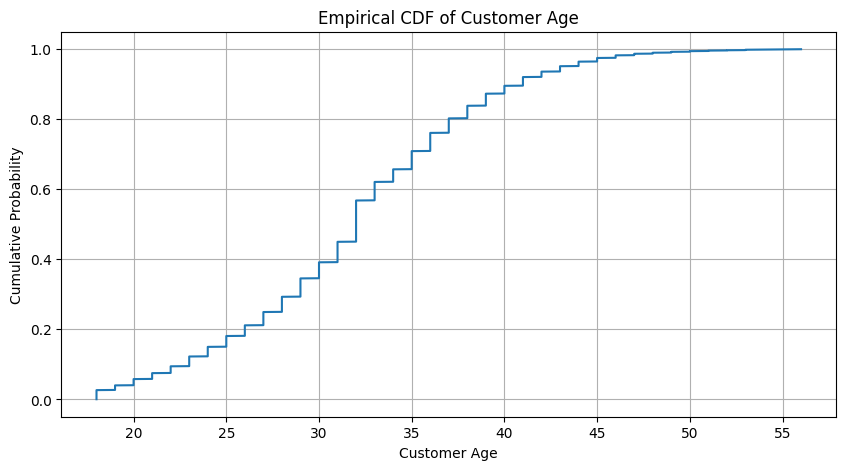

In [1154]:
age_sorted = np.sort(data['age'])

age_cumulative_probability = (
    np.arange(1, len(age_sorted) + 1)
    / len(age_sorted)
)

plt.figure(figsize=(10, 5))

plt.plot(age_sorted, age_cumulative_probability)

plt.title('Empirical CDF of Customer Age')
plt.xlabel('Customer Age')
plt.ylabel('Cumulative Probability')

plt.grid()
plt.show()

This means that roughly 70% of QuickBite's customers are aged 35 or below, while the remaining 30% are older than 35.

In [1155]:
percentage = (data['age'] <= 35).mean() * 100

print(f"Customers aged 35 or below: {percentage:.2f}%")

Customers aged 35 or below: 70.90%


In [1156]:
# Z-score outlier analysis

In [1157]:
from scipy import stats

delivery_zscores = stats.zscore(data['delivery_time_min'])

delivery_outliers = data[
    np.abs(delivery_zscores) > 3
]

print("Number of Z-score outliers:", len(delivery_outliers))

delivery_outliers[
    ['customer_id', 'delivery_time_min']
].sort_values(
    by='delivery_time_min',
    ascending=False
)

Number of Z-score outliers: 4


,customer_id,delivery_time_min
1417,QB101417,500.0
1210,QB101210,410.0
1293,QB101293,320.0
1223,QB101223,275.0


The IQR method identified 53 potential delivery-time outliers, while the Z-score method identified four extreme observations (275–500 minutes). These four records were flagged for operational investigation and retained to avoid hiding genuine delivery failures.

Log transformation of avg_order_value

In [1158]:
data['log_avg_order_value'] = np.log(
    data['avg_order_value']
)

In [1159]:
data[['avg_order_value', 'log_avg_order_value']].head()

,avg_order_value,log_avg_order_value
0,572.0,6.349139
1,329.0,5.796058
2,118.0,4.770685
3,303.0,5.713733
4,191.0,5.252273


Compare the distributions

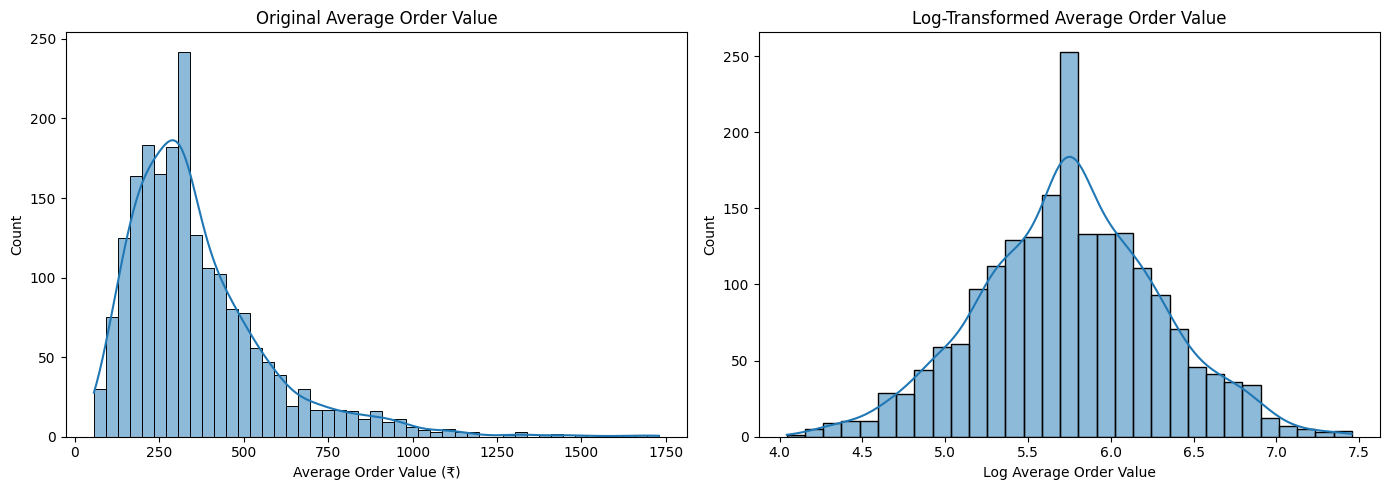

In [1160]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=data,
    x='avg_order_value',
    kde=True,
    ax=axes[0]
)

axes[0].set_title('Original Average Order Value')
axes[0].set_xlabel('Average Order Value (₹)')

sns.histplot(
    data=data,
    x='log_avg_order_value',
    kde=True,
    ax=axes[1]
)

axes[1].set_title('Log-Transformed Average Order Value')
axes[1].set_xlabel('Log Average Order Value')

plt.tight_layout()
plt.show()

compare the skewness

In [1161]:
print(
    "Original skewness:",
    data['avg_order_value'].skew()
)

print(
    "Log-transformed skewness:",
    data['log_avg_order_value'].skew()
)

Original skewness: 1.8291240328124119
Log-transformed skewness: -0.006704384833601575


Adding mean, median and mode to the distribution plot

In [1162]:
aov_mean = data['avg_order_value'].mean()
aov_median = data['avg_order_value'].median()
aov_mode = data['avg_order_value'].mode()[0]

print("Mean:", aov_mean)
print("Median:", aov_median)
print("Mode:", aov_mode)

Mean: 364.6095
Median: 316.0
Mode: 325.0


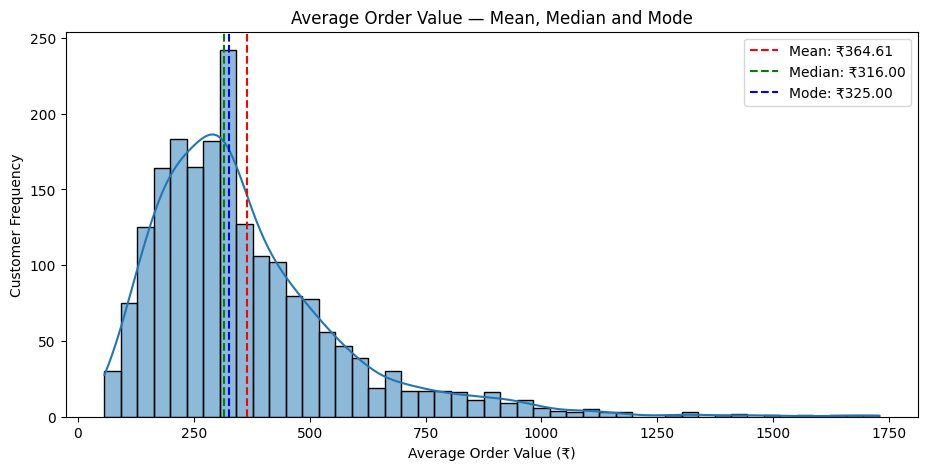

In [1163]:
plt.figure(figsize=(11, 5))

sns.histplot(
    data=data,
    x='avg_order_value',
    kde=True
)

plt.axvline(
    aov_mean,
    color='red',
    linestyle='--',
    label=f'Mean: ₹{aov_mean:.2f}'
)

plt.axvline(
    aov_median,
    color='green',
    linestyle='--',
    label=f'Median: ₹{aov_median:.2f}'
)

plt.axvline(
    aov_mode,
    color='blue',
    linestyle='--',
    label=f'Mode: ₹{aov_mode:.2f}'
)

plt.title('Average Order Value — Mean, Median and Mode')
plt.xlabel('Average Order Value (₹)')
plt.ylabel('Customer Frequency')
plt.legend()
plt.show()


age, orders_last_12m, annual_spend, and membership

In [1164]:
columns = [
    'age',
    'orders_last_12m',
    'annual_spend',
    'membership'
]

for col in columns:
    print(f"\n{col}")
    print("Mean:", data[col].mean() if data[col].dtype != 'object' else "Not applicable")
    print("Median:", data[col].median() if data[col].dtype != 'object' else "Not applicable")
    print("Mode:", data[col].mode()[0])


age
Mean: Not applicable
Median: Not applicable
Mode: 32.0

orders_last_12m
Mean: 34.8965
Median: 24.0
Mode: 17

annual_spend
Mean: 12995.852
Median: 7142.0
Mode: 2916.0

membership
Mean: Not applicable
Median: Not applicable
Mode: Basic


In [1169]:
print("Dataset shape:", data.shape)
print("Total missing values:", data.isna().sum().sum())
print("Duplicate customer IDs:", data['customer_id'].duplicated().sum())

Dataset shape: (2000, 30)
Total missing values: 0
Duplicate customer IDs: 0


Create the final clean dataset

In [1170]:
original_columns = [
    'customer_id',
    'signup_date',
    'city',
    'city_tier',
    'gender',
    'device_type',
    'acquisition_channel',
    'age',
    'tenure_months',
    'app_sessions_per_month',
    'delivery_time_min',
    'avg_order_value',
    'customer_rating',
    'discount_used_pct',
    'days_since_last_order',
    'membership',
    'orders_last_12m',
    'annual_spend'
]

clean_data = data[original_columns].copy()

In [1171]:
clean_data.to_csv(
    'quickbite_clean.csv',
    index=False
)

In [1172]:
print("Shape:", clean_data.shape)
print("Missing values:", clean_data.isna().sum().sum())
print("Duplicate IDs:", clean_data['customer_id'].duplicated().sum())

Shape: (2000, 18)
Missing values: 0
Duplicate IDs: 0
